# 01 — Data Understanding: Pemerataan Fasilitas Kesehatan Indonesia

**Tujuan notebook**
- Memahami struktur, kualitas, dan keterbatasan 4 dataset provinsi + 1 GeoJSON ADM2.
- Menemukan pola awal sebaran faskes, rasio per kapita, cakupan desa, dan ketimpangan.
- Menyiapkan daftar insight dan catatan data untuk analisis lanjutan (02–05) dan dashboard.

**Data yang tersedia**

| Dataset | Level | Periode | Isi |
|---|---|---|---|
| `penduduk_provinsi_2026.csv` | Provinsi | 2026 (proyeksi) | Penduduk, kepadatan, pertumbuhan, sex ratio |
| `desa_kelurahan_provinsi_2025.csv` | Provinsi | 2025 | Jumlah desa/kelurahan |
| `desa_kelurahan_sarana_kesehatan_2025.csv` | Provinsi | 2025 | Desa yang memiliki 7 jenis sarana kesehatan |
| `rs_puskesmas_provinsi_2025.csv` | Provinsi | 2025 | RS umum/khusus, puskesmas rawat inap/non-inap |
| `geoBoundaries-IDN-ADM2_simplified.geojson` | Kabupaten/kota | 2020/2025 | Batas ADM2, 519 fitur |

**Pertanyaan EDA**
1. Seberapa timpang sebaran faskes antarprovinsi?
2. Apakah kesimpulan berubah jika ukurannya per kapita, per luas, atau per desa?
3. Di mana data belum bisa menjawab “pemerataan” secara valid?

## 0. Setup

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from matplotlib.colors import LogNorm
from IPython.display import display

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 10

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"

print("ROOT :", ROOT)
print("\nFile di data/raw:")
for p in sorted(RAW.glob("*")):
    print(f" - {p.name:55s} {p.stat().st_size/1e6:8.2f} MB")

ROOT : C:\Kuliah\Semester 5\Presentasi Data and Storytelling\pemerataan-faskes-indonesia

File di data/raw:
 - desa_kelurahan_provinsi_2025.csv                            0.00 MB
 - desa_kelurahan_sarana_kesehatan_2025.csv                    0.00 MB
 - geoBoundaries-IDN-ADM2_simplified.geojson                  11.00 MB
 - penduduk_provinsi_2026.csv                                  0.00 MB
 - rs_puskesmas_provinsi_2025.csv                              0.00 MB


## 1. Helper functions

In [2]:
MISSING_TOKENS = {"�", "-", "", "NA", "N/A", "n/a"}
DROP_ROWS = {"Indonesia", "Keterangan"}

def load_province_csv(filename):
    df = pd.read_csv(RAW / filename, dtype=str, keep_default_na=False)
    df.columns = [c.strip() for c in df.columns]
    df["Provinsi"] = df["Provinsi"].astype(str).str.strip()
    df = df[~df["Provinsi"].isin(DROP_ROWS)]
    df = df[~df["Provinsi"].str.match(r"^\d")]
    df = df[~df["Provinsi"].str.startswith("Data Puskesmas")]
    df = df[df["Provinsi"] != ""]
    for c in df.columns:
        if c != "Provinsi":
            df[c] = df[c].replace(list(MISSING_TOKENS), np.nan)
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df.reset_index(drop=True)

def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    return (2 * np.sum(np.arange(1, n + 1) * x) / (n * np.sum(x))) - (n + 1) / n

def theil(x):
    x = np.asarray(x, dtype=float)
    mu = x.mean()
    return np.mean((x / mu) * np.log(x / mu))

def lorenz(x):
    x = np.sort(np.asarray(x, dtype=float))
    cum = np.cumsum(x)
    return np.insert(np.arange(1, len(x) + 1) / len(x), 0, 0), np.insert(cum / cum[-1], 0, 0)

def top_bottom(df, col, n=3, cols=None, decimals=2):
    cols = cols or ["Provinsi", col]
    top = df.nlargest(n, col)[cols].assign(keterangan="tertinggi")
    bot = df.nsmallest(n, col)[cols].assign(keterangan="terendah")
    out = pd.concat([top, bot], ignore_index=True)
    return out.round(decimals)

print("Helper siap.")

Helper siap.


## 2. Inventaris data mentah

In [3]:
files = {
    "penduduk_provinsi_2026.csv": "Penduduk, kepadatan, pertumbuhan, sex ratio",
    "desa_kelurahan_provinsi_2025.csv": "Jumlah desa/kelurahan",
    "desa_kelurahan_sarana_kesehatan_2025.csv": "Desa yang memiliki 7 jenis sarana kesehatan",
    "rs_puskesmas_provinsi_2025.csv": "Jumlah RS umum/khusus & puskesmas inap/non-inap",
}
rows = []
for f, desc in files.items():
    df = pd.read_csv(RAW / f)
    rows.append({"file": f, "deskripsi": desc, "baris": len(df), "kolom": df.shape[1]})
display(pd.DataFrame(rows))

for f in files:
    print(f"\n=== {f} — 3 baris terakhir ===")
    tail = pd.read_csv(RAW / f).tail(3).iloc[:, :3].copy()
    for c in tail.columns:
        tail[c] = tail[c].astype(str).str.slice(0, 75)
    display(tail)

,file,deskripsi,baris,kolom
0,penduduk_provinsi_2026.csv,"Penduduk, kepadatan, pertumbuhan, sex ratio",42,6
1,desa_kelurahan_provinsi_2025.csv,Jumlah desa/kelurahan,39,2
2,desa_kelurahan_sarana_kesehatan_2025.csv,Desa yang memiliki 7 jenis sarana kesehatan,43,8
3,rs_puskesmas_provinsi_2025.csv,Jumlah RS umum/khusus & puskesmas inap/non-inap,42,5



=== penduduk_provinsi_2026.csv — 3 baris terakhir ===


,Provinsi,Jumlah Penduduk (Ribu),Laju Pertumbuhan Penduduk per Tahun
39,nan,nan,nan
40,Keterangan,nan,nan
41,1Proyeksi Penduduk Indonesia 2020-2050 Hasil S...,nan,nan



=== desa_kelurahan_provinsi_2025.csv — 3 baris terakhir ===


,Provinsi,Jumlah Desa
36,Papua Tengah,1208
37,Papua Pegunungan,2634
38,Indonesia,84291



=== desa_kelurahan_sarana_kesehatan_2025.csv — 3 baris terakhir ===


,Provinsi,Desa/Kelurahan Yang Memiliki Sarana Kesehatan - Rumah Sakit,Desa/Kelurahan Yang Memiliki Sarana Kesehatan - Puskesmas
40,Keterangan,nan,nan
41,1Desa pada tabel ini termasuk Unit Permukiman ...,nan,nan
42,2Data provinsi tidak mencakup sebagian desa/ke...,nan,nan



=== rs_puskesmas_provinsi_2025.csv — 3 baris terakhir ===


,Provinsi,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus
39,nan,nan,nan
40,Keterangan,nan,nan
41,Data Puskesmas berdasarkan Keputusan Menteri K...,nan,nan


**Insight inventaris**
- File mentah berukuran kecil (KB), tetapi **bukan tabel bersih**: setiap file punya baris `Indonesia`, baris kosong, `Keterangan`, dan catatan kaki.
- `penduduk` 42 baris, `desa` 39 baris, `sarana` 43 baris, `rs` 42 baris — setelah dibersihkan semuanya menjadi **38 provinsi**.
- Ada karakter `�` yang dipakai sebagai penanda data tidak tersedia:
  - `Jumlah Rumah Sakit Khusus`: 6 provinsi.
  - `Desa/Kelurahan Yang Memiliki Sarana Kesehatan - Balai Kesehatan`: 21 provinsi.
- Tahun tidak seragam: penduduk 2026, desa/sarana/RS 2025, tetapi catatan RS menyebut data puskesmas semester I 2024 (dan teks Inggris menyebut 2023).

### 2.1 Muat data bersih dan cek konsistensi provinsi

In [4]:
pend = load_province_csv("penduduk_provinsi_2026.csv")
desa = load_province_csv("desa_kelurahan_provinsi_2025.csv")
sar = load_province_csv("desa_kelurahan_sarana_kesehatan_2025.csv")
rs = load_province_csv("rs_puskesmas_provinsi_2025.csv")

for name, df in [("penduduk", pend), ("desa", desa), ("sarana", sar), ("rs", rs)]:
    print(f"{name:8s} shape={df.shape}  provinsi_unik={df['Provinsi'].nunique()}  duplikat={df['Provinsi'].duplicated().sum()}")

print("\nSet provinsi identik:", set(pend.Provinsi) == set(desa.Provinsi) == set(sar.Provinsi) == set(rs.Provinsi))
print("Jumlah provinsi:", len(set(pend.Provinsi)))
print("\nDaftar provinsi:")
print(sorted(pend.Provinsi.tolist()))

penduduk shape=(38, 6)  provinsi_unik=38  duplikat=0


desa     shape=(38, 2)  provinsi_unik=38  duplikat=0
sarana   shape=(38, 8)  provinsi_unik=38  duplikat=0
rs       shape=(38, 5)  provinsi_unik=38  duplikat=0

Set provinsi identik: True
Jumlah provinsi: 38

Daftar provinsi:
['Aceh', 'Bali', 'Banten', 'Bengkulu', 'DI Yogyakarta', 'DKI Jakarta', 'Gorontalo', 'Jambi', 'Jawa Barat', 'Jawa Tengah', 'Jawa Timur', 'Kalimantan Barat', 'Kalimantan Selatan', 'Kalimantan Tengah', 'Kalimantan Timur', 'Kalimantan Utara', 'Kepulauan Bangka Belitung', 'Kepulauan Riau', 'Lampung', 'Maluku', 'Maluku Utara', 'Nusa Tenggara Barat', 'Nusa Tenggara Timur', 'Papua', 'Papua Barat', 'Papua Barat Daya', 'Papua Pegunungan', 'Papua Selatan', 'Papua Tengah', 'Riau', 'Sulawesi Barat', 'Sulawesi Selatan', 'Sulawesi Tengah', 'Sulawesi Tenggara', 'Sulawesi Utara', 'Sumatera Barat', 'Sumatera Selatan', 'Sumatera Utara']


### 2.2 Rename kolom dan cek missing value

In [5]:
sar = sar.rename(columns={
    "Desa/Kelurahan Yang Memiliki Sarana Kesehatan - Rumah Sakit": "desa_rs",
    "Desa/Kelurahan Yang Memiliki Sarana Kesehatan - Puskesmas": "desa_pkm",
    "Desa/Kelurahan Yang Memiliki Sarana Kesehatan - Puskesmas Pembantu": "desa_pustu",
    "Desa/Kelurahan Yang Memiliki Sarana Kesehatan - Apotek": "desa_apotek",
    "Desa/Kelurahan Yang Memiliki Sarana Kesehatan - Klinik Utama (Unit)": "desa_klinik_utama",
    "Desa/Kelurahan Yang Memiliki Sarana Kesehatan - Balai Kesehatan": "desa_balai",
    "Desa/Kelurahan Yang Memiliki Sarana Kesehatan - Klinik Pratama": "desa_klinik_pratama",
})

rs = rs.rename(columns={
    "Jumlah Rumah Sakit Umum": "rsu",
    "Jumlah Rumah Sakit Khusus": "rsk",
    "Jumlah Puskesmas Rawat Inap": "pkm_ri",
    "Jumlah Puskesmas Non Rawat Inap": "pkm_nri",
})

print("Kolom sarana:", sar.columns.tolist())
print("Kolom RS    :", rs.columns.tolist())

print("\nMissing pada sarana:")
for c in sar.columns[1:]:
    n = int(sar[c].isna().sum())
    if n:
        print(f" - {c}: {n} provinsi -> {sar.loc[sar[c].isna(), 'Provinsi'].tolist()}")

print("\nMissing pada RS:")
for c in rs.columns[1:]:
    n = int(rs[c].isna().sum())
    if n:
        print(f" - {c}: {n} provinsi -> {rs.loc[rs[c].isna(), 'Provinsi'].tolist()}")

Kolom sarana: ['Provinsi', 'desa_rs', 'desa_pkm', 'desa_pustu', 'desa_apotek', 'desa_klinik_utama', 'desa_balai', 'desa_klinik_pratama']
Kolom RS    : ['Provinsi', 'rsu', 'rsk', 'pkm_ri', 'pkm_nri']

Missing pada sarana:
 - desa_balai: 21 provinsi -> ['Riau', 'Jambi', 'Sumatera Selatan', 'Bengkulu', 'Lampung', 'Kepulauan Bangka Belitung', 'DI Yogyakarta', 'Jawa Timur', 'Bali', 'Kalimantan Barat', 'Kalimantan Tengah', 'Kalimantan Timur', 'Kalimantan Utara', 'Sulawesi Tenggara', 'Gorontalo', 'Sulawesi Barat', 'Maluku Utara', 'Papua Barat', 'Papua', 'Papua Selatan', 'Papua Pegunungan']

Missing pada RS:
 - rsk: 6 provinsi -> ['Kalimantan Utara', 'Papua Barat', 'Papua Barat Daya', 'Papua Selatan', 'Papua Tengah', 'Papua Pegunungan']


**Insight kualitas data**
- Missing **bukan nol**: 6 provinsi tidak punya nilai RS Khusus (Kalimantan Utara, Papua Barat, Papua Barat Daya, Papua Selatan, Papua Tengah, Papua Pegunungan).
- Balai Kesehatan hanya terisi di 17 provinsi; 21 provinsi lain `�`. Indikator ini terlalu jarang untuk dijadikan ukuran utama.
- Jangan langsung `fillna(0)` untuk RS Khusus. Untuk analisis utama, lebih aman pakai **RSU saja** atau tampilkan dua versi: `total_rs` (NaN) dan `total_rs_est` (RS Khusus dianggap 0).

### 2.3 Validasi total 38 provinsi vs baris `Indonesia`

In [6]:
raw = {f: pd.read_csv(RAW / f) for f in files}

def indonesia_value(df, col):
    val = pd.to_numeric(df.loc[df["Provinsi"] == "Indonesia", col], errors="coerce")
    return val.iloc[0] if len(val) else np.nan

checks = []
checks.append({"dataset": "penduduk", "kolom": "Jumlah Penduduk (Ribu)",
               "sum_38_provinsi": pend["Jumlah Penduduk (Ribu)"].sum(),
               "baris_indonesia": indonesia_value(raw["penduduk_provinsi_2026.csv"], "Jumlah Penduduk (Ribu)")})
checks.append({"dataset": "desa", "kolom": "Jumlah Desa",
               "sum_38_provinsi": desa["Jumlah Desa"].sum(),
               "baris_indonesia": indonesia_value(raw["desa_kelurahan_provinsi_2025.csv"], "Jumlah Desa")})

sar_raw = raw["desa_kelurahan_sarana_kesehatan_2025.csv"]
sar_old = [c for c in sar_raw.columns if c != "Provinsi"]
for old, new in zip(sar_old, sar.columns[1:]):
    checks.append({"dataset": "sarana", "kolom": new,
                   "sum_38_provinsi": sar[new].sum(),
                   "baris_indonesia": indonesia_value(sar_raw, old)})

rs_raw = raw["rs_puskesmas_provinsi_2025.csv"]
rs_old = [c for c in rs_raw.columns if c != "Provinsi"]
for old, new in zip(rs_old, rs.columns[1:]):
    checks.append({"dataset": "rs", "kolom": new,
                   "sum_38_provinsi": rs[new].sum(),
                   "baris_indonesia": indonesia_value(rs_raw, old)})

checks = pd.DataFrame(checks)
checks["selisih"] = checks["sum_38_provinsi"] - checks["baris_indonesia"]
display(checks.round(2))

,dataset,kolom,sum_38_provinsi,baris_indonesia,selisih
0,penduduk,Jumlah Penduduk (Ribu),287198.4,287198.4,0.0
1,desa,Jumlah Desa,84291.0,84291.0,0.0
2,sarana,desa_rs,2802.0,2802.0,0.0
3,sarana,desa_pkm,10254.0,10254.0,0.0
4,sarana,desa_pustu,24815.0,24815.0,0.0
5,sarana,desa_apotek,18998.0,18998.0,0.0
6,sarana,desa_klinik_utama,1501.0,1501.0,0.0
7,sarana,desa_balai,93.0,93.0,0.0
8,sarana,desa_klinik_pratama,8958.0,8958.0,0.0
9,rs,rsu,2770.0,2770.0,0.0


**Insight validasi**
- Semua total 38 provinsi **sama persis** dengan baris `Indonesia` (selisih 0), termasuk kolom yang punya missing.
- Artinya, untuk kolom yang `�`, nilai Indonesia juga tidak memasukkan provinsi tersebut — atau nilainya memang 0. Ini memperkuat pentingnya **flag missing**, bukan asumsi 0.
- Konsistensi total ini membuat data aman dipakai untuk agregasi nasional, tetapi belum tentu aman untuk perbandingan antarprovinsi pada kolom yang missing.

## 3. Dataset penduduk (2026)

In [7]:
display(pend.describe().T.round(2))

display(top_bottom(pend, "Jumlah Penduduk (Ribu)", n=5,
                   cols=["Provinsi", "Jumlah Penduduk (Ribu)", "Persentase Penduduk", "Kepadatan Penduduk per km persegi (Km2)"]))
display(top_bottom(pend, "Kepadatan Penduduk per km persegi (Km2)", n=5,
                   cols=["Provinsi", "Kepadatan Penduduk per km persegi (Km2)", "Jumlah Penduduk (Ribu)"]))
display(top_bottom(pend, "Laju Pertumbuhan Penduduk per Tahun", n=3,
                   cols=["Provinsi", "Laju Pertumbuhan Penduduk per Tahun"]))
display(top_bottom(pend, "Rasio Jenis Kelamin Penduduk", n=3,
                   cols=["Provinsi", "Rasio Jenis Kelamin Penduduk"]))

,count,mean,std,min,25%,50%,75%,max
Jumlah Penduduk (Ribu),38.0,7557.85,11500.91,557.20,1552.98,3807.20,6667.20,51163.90
Laju Pertumbuhan Penduduk per Tahun,38.0,1.28,0.43,0.18,1.12,1.32,1.43,3.06
Persentase Penduduk,38.0,2.63,4.00,0.19,0.54,1.33,2.32,17.81
Kepadatan Penduduk per km persegi (Km2),38.0,682.00,2603.74,5.00,40.75,102.00,261.50,16129.00
Rasio Jenis Kelamin Penduduk,38.0,103.89,3.74,97.70,101.28,103.05,105.10,113.50


,Provinsi,Jumlah Penduduk (Ribu),Persentase Penduduk,Kepadatan Penduduk per km persegi (Km2),keterangan
0,Jawa Barat,51163.9,17.81,1381,tertinggi
1,Jawa Timur,42352.0,14.75,881,tertinggi
2,Jawa Tengah,38565.0,13.43,1123,tertinggi
3,Sumatera Utara,15978.6,5.56,221,tertinggi
4,Banten,12641.3,4.40,1351,tertinggi
5,Papua Selatan,557.2,0.19,5,terendah
6,Papua Barat,596.5,0.21,10,terendah
7,Papua Barat Daya,645.5,0.22,17,terendah
8,Kalimantan Utara,758.8,0.26,11,terendah
9,Papua,1086.5,0.38,13,terendah


,Provinsi,Kepadatan Penduduk per km persegi (Km2),Jumlah Penduduk (Ribu),keterangan
0,DKI Jakarta,16129,10669.7,tertinggi
1,Jawa Barat,1381,51163.9,tertinggi
2,Banten,1351,12641.3,tertinggi
3,DI Yogyakarta,1199,3802.7,tertinggi
4,Jawa Tengah,1123,38565.0,tertinggi
5,Papua Selatan,5,557.2,terendah
6,Papua Barat,10,596.5,terendah
7,Kalimantan Utara,11,758.8,terendah
8,Papua,13,1086.5,terendah
9,Papua Barat Daya,17,645.5,terendah


,Provinsi,Laju Pertumbuhan Penduduk per Tahun,keterangan
0,Kalimantan Timur,3.06,tertinggi
1,Papua Barat,1.65,tertinggi
2,Sulawesi Tenggara,1.63,tertinggi
3,DKI Jakarta,0.18,terendah
4,DI Yogyakarta,0.63,terendah
5,Bali,0.68,terendah


,Provinsi,Rasio Jenis Kelamin Penduduk,keterangan
0,Papua Pegunungan,113.5,tertinggi
1,Papua Tengah,113.1,tertinggi
2,Papua Barat,110.2,tertinggi
3,DI Yogyakarta,97.7,terendah
4,Sulawesi Selatan,98.8,terendah
5,Jawa Timur,99.3,terendah


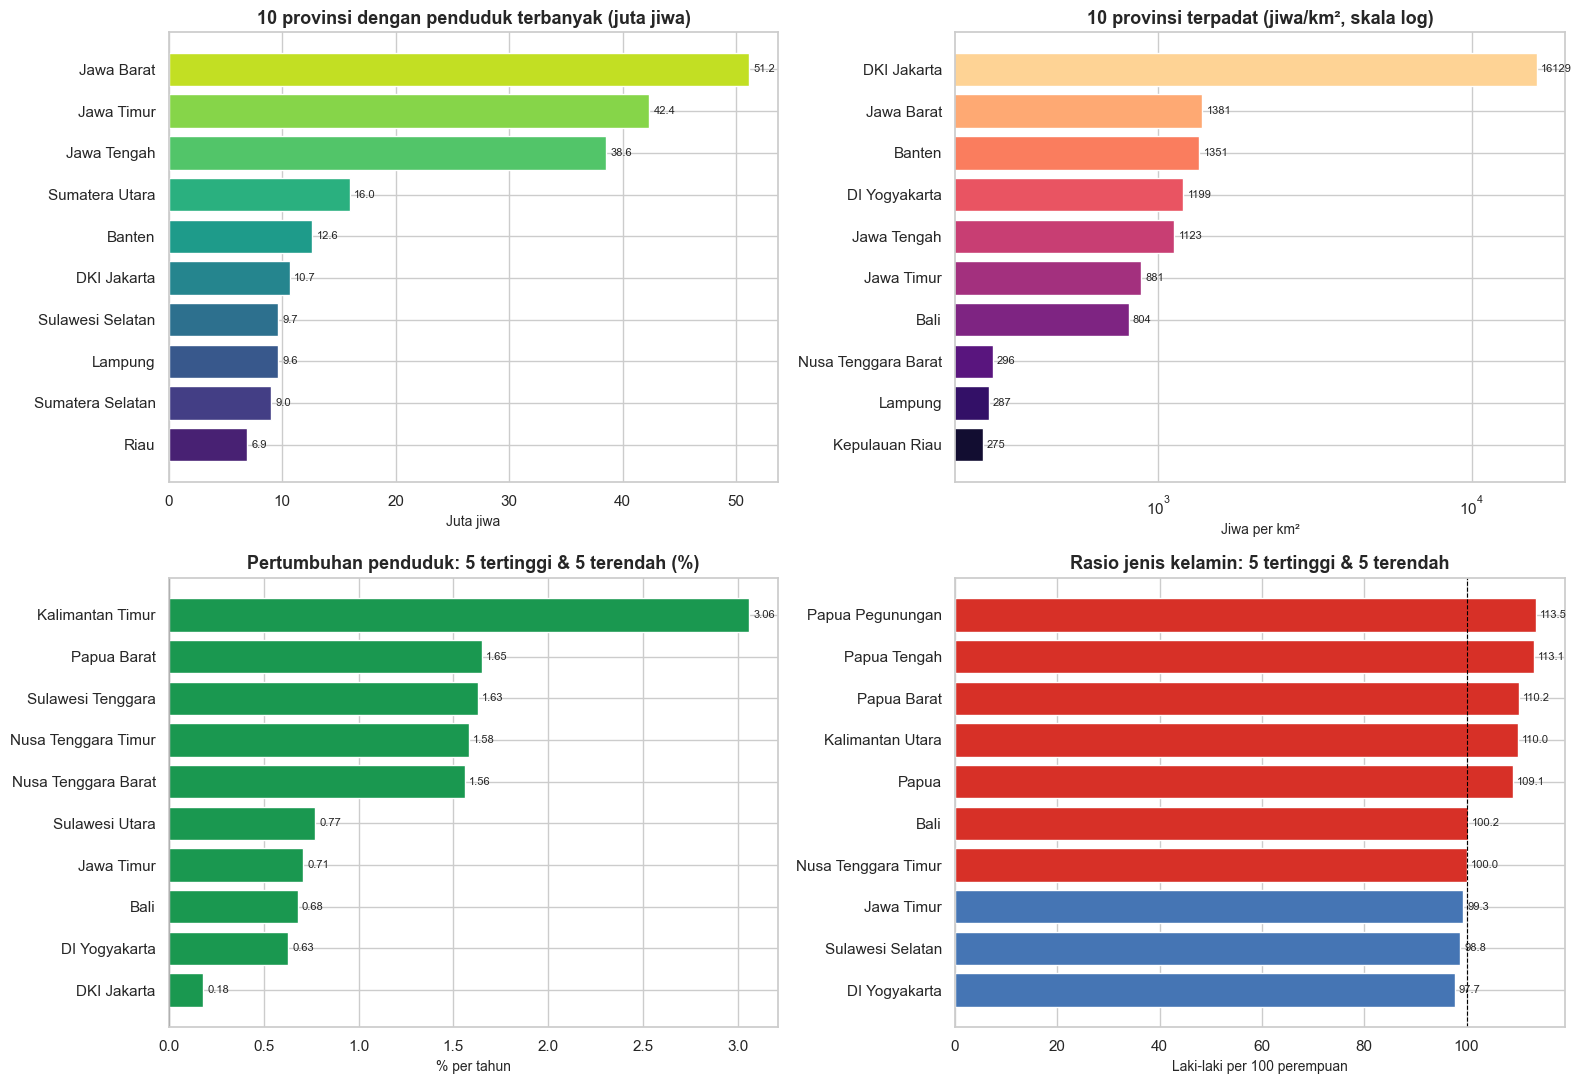

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

top = pend.nlargest(10, "Jumlah Penduduk (Ribu)").sort_values("Jumlah Penduduk (Ribu)")
axes[0, 0].barh(top["Provinsi"], top["Jumlah Penduduk (Ribu)"] / 1000, color=sns.color_palette("viridis", 10))
axes[0, 0].set_title("10 provinsi dengan penduduk terbanyak (juta jiwa)")
axes[0, 0].set_xlabel("Juta jiwa")
axes[0, 0].bar_label(axes[0, 0].containers[0], fmt="%.1f", padding=3, fontsize=8)

top = pend.nlargest(10, "Kepadatan Penduduk per km persegi (Km2)").sort_values("Kepadatan Penduduk per km persegi (Km2)")
axes[0, 1].barh(top["Provinsi"], top["Kepadatan Penduduk per km persegi (Km2)"], color=sns.color_palette("magma", 10))
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("10 provinsi terpadat (jiwa/km², skala log)")
axes[0, 1].set_xlabel("Jiwa per km²")
axes[0, 1].bar_label(axes[0, 1].containers[0], fmt="%.0f", padding=3, fontsize=8)

g = pd.concat([
    pend.nlargest(5, "Laju Pertumbuhan Penduduk per Tahun"),
    pend.nsmallest(5, "Laju Pertumbuhan Penduduk per Tahun"),
]).sort_values("Laju Pertumbuhan Penduduk per Tahun")
colors = ["#d73027" if v < 0 else "#1a9850" for v in g["Laju Pertumbuhan Penduduk per Tahun"]]
axes[1, 0].barh(g["Provinsi"], g["Laju Pertumbuhan Penduduk per Tahun"], color=colors)
axes[1, 0].axvline(0, color="black", linewidth=0.8)
axes[1, 0].set_title("Pertumbuhan penduduk: 5 tertinggi & 5 terendah (%)")
axes[1, 0].set_xlabel("% per tahun")
axes[1, 0].bar_label(axes[1, 0].containers[0], fmt="%.2f", padding=3, fontsize=8)

s = pd.concat([
    pend.nlargest(5, "Rasio Jenis Kelamin Penduduk"),
    pend.nsmallest(5, "Rasio Jenis Kelamin Penduduk"),
]).sort_values("Rasio Jenis Kelamin Penduduk")
colors = ["#4575b4" if v < 100 else "#d73027" for v in s["Rasio Jenis Kelamin Penduduk"]]
axes[1, 1].barh(s["Provinsi"], s["Rasio Jenis Kelamin Penduduk"], color=colors)
axes[1, 1].axvline(100, color="black", linestyle="--", linewidth=0.8)
axes[1, 1].set_title("Rasio jenis kelamin: 5 tertinggi & 5 terendah")
axes[1, 1].set_xlabel("Laki-laki per 100 perempuan")
axes[1, 1].bar_label(axes[1, 1].containers[0], fmt="%.1f", padding=3, fontsize=8)

plt.tight_layout()
plt.show()

**Insight penduduk**
- **Konsentrasi ekstrem di Jawa**: Jawa Barat 17,81%, Jawa Timur 14,75%, Jawa Tengah 13,43%, Sumatera Utara 5,56%, Banten 4,40%. Lima provinsi ini menampung **55,95%** penduduk Indonesia.
- **Kepadatan**: DKI Jakarta 16.129 jiwa/km² vs Papua Selatan 5 jiwa/km² — selisih **>3.200 kali**. Ini alasan utama mengapa ukuran “per kapita” dan “per luas” akan memberi kesimpulan berbeda.
- **Pertumbuhan**: Kalimantan Timur tertinggi (3,06%/tahun), DKI terendah (0,18%). Pertumbuhan tinggi di Kaltim bisa menambah tekanan faskes di masa depan.
- **Sex ratio**: Papua Pegunungan 113,5 (paling maskulin), DI Yogyakarta 97,7 (paling feminin). Bisa relevan untuk kebutuhan layanan ibu/anak, tetapi bukan indikator utama pemerataan faskes.
- **Populasi per desa** (dihitung nanti): DKI 39.961 jiwa/desa vs Papua Pegunungan 570 jiwa/desa — proxy urbanitas yang sangat kuat.
- **Implikasi**: jumlah faskes absolut akan selalu condong ke Jawa; rasio per kapita akan condong ke provinsi berpenduduk sedikit. Tidak ada satu metrik yang netral.

## 4. Dataset desa/kelurahan (2025)

,count,mean,std,min,25%,50%,75%,max
Jumlah Desa,38.0,2218.184211,2141.196166,267.0,984.75,1532.5,2548.5,8563.0


,Provinsi,Jumlah Desa,keterangan
0,Jawa Tengah,8563,tertinggi
1,Jawa Timur,8494,tertinggi
2,Aceh,6513,tertinggi
3,Sumatera Utara,6113,tertinggi
4,Jawa Barat,5957,tertinggi
5,DKI Jakarta,267,terendah
6,Kepulauan Bangka Belitung,393,terendah
7,Kepulauan Riau,430,terendah
8,DI Yogyakarta,438,terendah
9,Kalimantan Utara,484,terendah


,Provinsi,Jumlah Desa,Jumlah Penduduk (Ribu),pop_per_desa,keterangan
0,DKI Jakarta,267,10669.7,39961.4,tertinggi
1,DI Yogyakarta,438,3802.7,8682.0,tertinggi
2,Jawa Barat,5957,51163.9,8588.9,tertinggi
3,Banten,1552,12641.3,8145.2,tertinggi
4,Bali,718,4488.2,6251.0,tertinggi
5,Papua Pegunungan,2634,1501.9,570.2,terendah
6,Papua Barat Daya,1056,645.5,611.3,terendah
7,Papua Barat,970,596.5,614.9,terendah
8,Papua Selatan,690,557.2,807.5,terendah
9,Aceh,6513,5695.9,874.5,terendah


Spearman populasi vs jumlah desa: 0.605


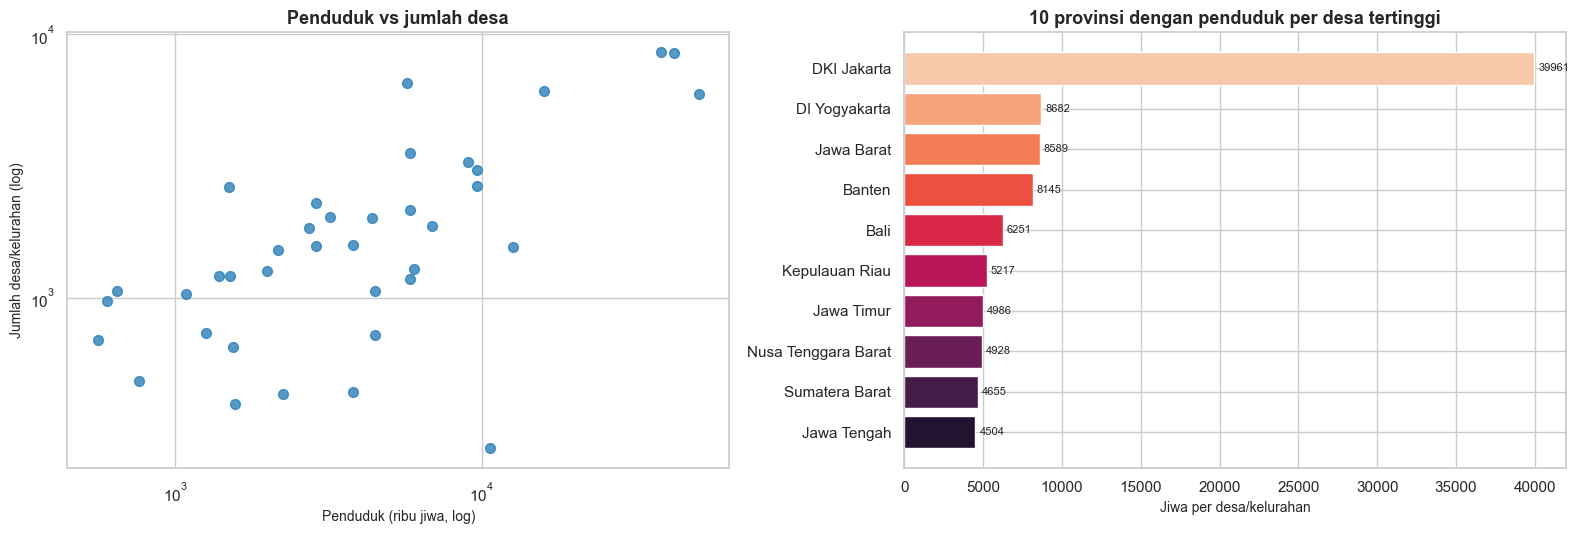

In [9]:
display(desa.describe().T)

display(top_bottom(desa, "Jumlah Desa", n=5))

tmp = pend.merge(desa, on="Provinsi")
tmp["pop_per_desa"] = tmp["Jumlah Penduduk (Ribu)"] * 1000 / tmp["Jumlah Desa"]
display(top_bottom(tmp, "pop_per_desa", n=5,
                   cols=["Provinsi", "Jumlah Desa", "Jumlah Penduduk (Ribu)", "pop_per_desa"], decimals=1))

print("Spearman populasi vs jumlah desa:", round(tmp[["Jumlah Penduduk (Ribu)", "Jumlah Desa"]].corr(method="spearman").iloc[0, 1], 3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].scatter(tmp["Jumlah Penduduk (Ribu)"], tmp["Jumlah Desa"], s=50, alpha=0.8, color="#2c7fb8")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Penduduk (ribu jiwa, log)")
axes[0].set_ylabel("Jumlah desa/kelurahan (log)")
axes[0].set_title("Penduduk vs jumlah desa")

top = tmp.nlargest(10, "pop_per_desa").sort_values("pop_per_desa")
axes[1].barh(top["Provinsi"], top["pop_per_desa"], color=sns.color_palette("rocket", 10))
axes[1].set_title("10 provinsi dengan penduduk per desa tertinggi")
axes[1].set_xlabel("Jiwa per desa/kelurahan")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f", padding=3, fontsize=8)

plt.tight_layout()
plt.show()

**Insight desa**
- Total **84.291** desa/kelurahan. Jawa Tengah (8.563), Jawa Timur (8.494), dan Aceh (6.513) paling banyak; DKI Jakarta hanya 267.
- Jumlah desa berkorelasi sedang dengan populasi (Spearman **0,60**), tetapi tidak proporsional: Jawa punya banyak desa **dan** banyak orang; Papua punya banyak desa tetapi populasi kecil.
- **Penduduk per desa** adalah proxy urbanitas yang berguna: DKI 39.961, DI Yogyakarta 8.682, Jawa Barat 8.589 vs Papua Pegunungan 570, Papua Barat Daya 611, Papua Barat 615.
- Wilayah dengan penduduk per desa rendah cenderung punya **rasio faskes per kapita tinggi** tetapi **cakupan desa rendah** — pola yang akan muncul lagi di bagian berikutnya.
- Jumlah desa bukan ukuran kebutuhan faskes; ia lebih tepat dipakai sebagai denominator cakupan dan proxy kepadatan permukiman.

## 5. Dataset sarana kesehatan desa (2025)

,Fasilitas,Jumlah desa,Desa tanpa,Cakupan (%)
2,Puskesmas Pembantu,24815.0,59476.0,29.44
3,Apotek,18998.0,65293.0,22.54
1,Puskesmas,10254.0,74037.0,12.16
6,Klinik Pratama,8958.0,75333.0,10.63
0,Rumah Sakit,2802.0,81489.0,3.32
4,Klinik Utama,1501.0,82790.0,1.78
5,Balai Kesehatan,93.0,84198.0,0.11


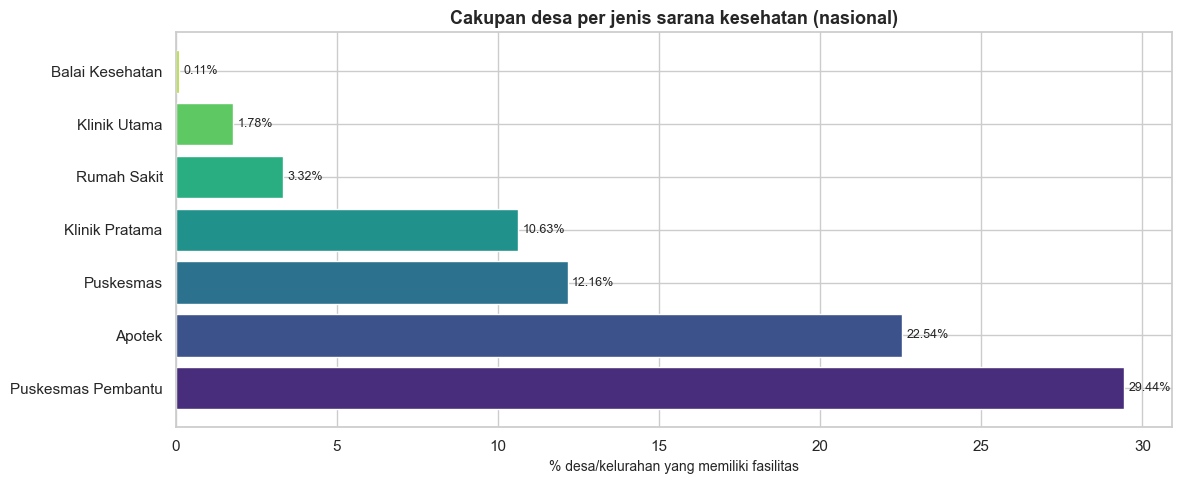

In [10]:
labels = {
    "desa_rs": "Rumah Sakit",
    "desa_pkm": "Puskesmas",
    "desa_pustu": "Puskesmas Pembantu",
    "desa_apotek": "Apotek",
    "desa_klinik_utama": "Klinik Utama",
    "desa_balai": "Balai Kesehatan",
    "desa_klinik_pratama": "Klinik Pratama",
}
total_desa = int(desa["Jumlah Desa"].sum())
coverage = pd.DataFrame({
    "Fasilitas": list(labels.values()),
    "Jumlah desa": [sar[c].sum() for c in labels],
    "Desa tanpa": [total_desa - sar[c].sum() for c in labels],
})
coverage["Cakupan (%)"] = coverage["Jumlah desa"] / total_desa * 100
coverage = coverage.sort_values("Cakupan (%)", ascending=False)
display(coverage.round(2))

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(coverage["Fasilitas"], coverage["Cakupan (%)"], color=sns.color_palette("viridis", len(coverage)))
ax.set_xlabel("% desa/kelurahan yang memiliki fasilitas")
ax.set_title("Cakupan desa per jenis sarana kesehatan (nasional)")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3, fontsize=9)
plt.tight_layout()
plt.show()

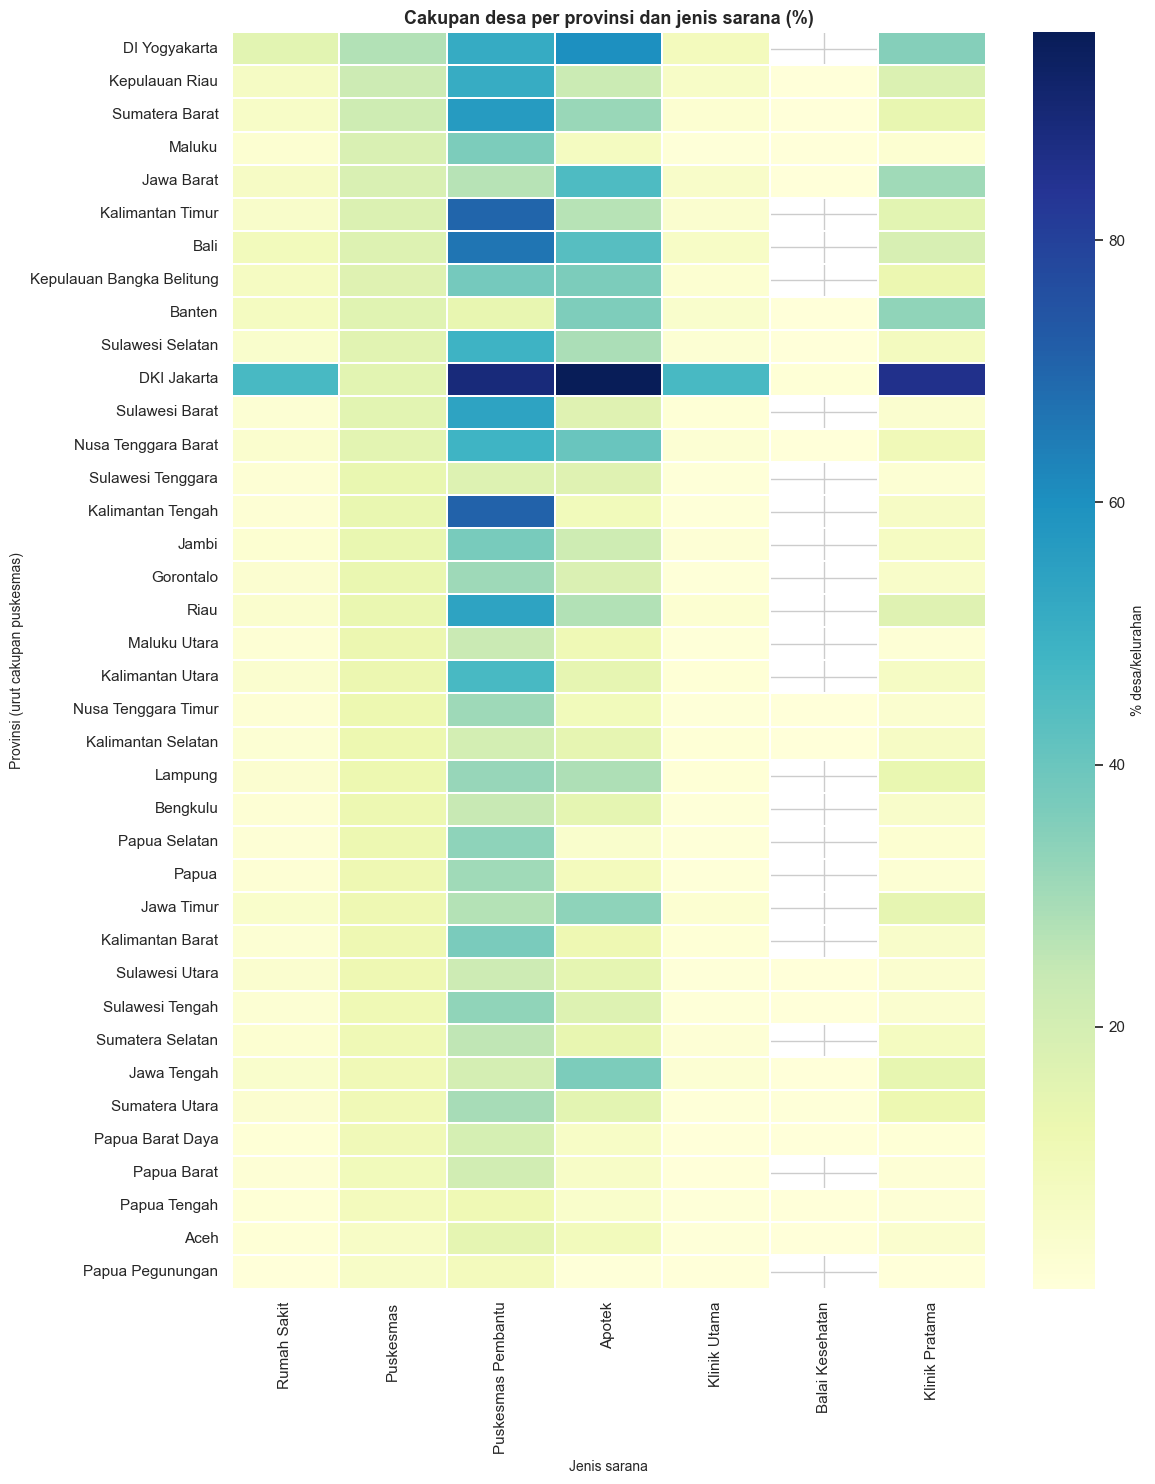

In [11]:
cov_pct = sar.set_index("Provinsi").div(desa.set_index("Provinsi")["Jumlah Desa"], axis=0) * 100
cov_pct = cov_pct.rename(columns=labels)
order = cov_pct["Puskesmas"].sort_values(ascending=False).index

plt.figure(figsize=(12, 15))
sns.heatmap(cov_pct.loc[order], cmap="YlGnBu", linewidths=0.3,
            cbar_kws={"label": "% desa/kelurahan"}, annot=False)
plt.title("Cakupan desa per provinsi dan jenis sarana (%)")
plt.xlabel("Jenis sarana")
plt.ylabel("Provinsi (urut cakupan puskesmas)")
plt.tight_layout()
plt.show()

**Insight cakupan desa**
- Secara nasional, **87,84% desa tidak memiliki puskesmas** dan **96,68% tidak memiliki RS**. Ini bukan berarti 87% desa tanpa akses, karena puskesmas/RS melayani wilayah sekitar — tetapi menunjukkan bahwa kehadiran faskes **di dalam desa** sangat terkonsentrasi.
- Sarana paling tersebar: **Puskesmas Pembantu (29,44%)**, **Apotek (22,54%)**, **Puskesmas (12,16%)**, **Klinik Pratama (10,63%)**.
- Sarana paling langka: **Balai Kesehatan (0,11%)**, **Klinik Utama (1,78%)**, **RS (3,32%)**.
- **DKI Jakarta** unggul untuk RS (46,82%), apotek (95,88%), klinik utama (46,82%), klinik pratama (85,77%), dan pustu (89,14%). Namun cakupan puskesmas hanya **16,53%** — DKI lebih bergantung pada RS, klinik, dan apotek daripada puskesmas.
- **Papua Pegunungan** terendah untuk hampir semua: RS 0,34%, puskesmas 5,54%, apotek 0,42%, klinik utama 0,04%, klinik pratama 0,34%, pustu 8,62%.
- Cakupan tiap jenis sarana **tidak boleh dijumlahkan**: satu desa bisa punya beberapa fasilitas sekaligus, dan data tidak memberi tahu overlap-nya.
- `Balai Kesehatan` tidak layak jadi indikator utama: hanya 93 desa (0,11%) dan missing di 21 provinsi.

## 6. Dataset RS & puskesmas (2025)

In [12]:
rs2 = rs.copy()
rs2["total_rs"] = rs2.rsu + rs2.rsk
rs2["total_rs_est"] = rs2.rsu + rs2.rsk.fillna(0)
rs2["total_pkm"] = rs2.pkm_ri + rs2.pkm_nri
rs2 = rs2.merge(pend[["Provinsi", "Jumlah Penduduk (Ribu)"]], on="Provinsi")
rs2["pop"] = rs2["Jumlah Penduduk (Ribu)"] * 1000
rs2["rs_per100k"] = rs2.total_rs_est / rs2["pop"] * 1e5
rs2["pkm_per100k"] = rs2.total_pkm / rs2["pop"] * 1e5

display(rs2[["rsu", "rsk", "pkm_ri", "pkm_nri", "total_rs_est", "total_pkm"]].sum().to_frame("total_nasional").T)

display(top_bottom(rs2, "total_pkm", n=5,
                   cols=["Provinsi", "pkm_ri", "pkm_nri", "total_pkm"]))
display(top_bottom(rs2, "pkm_per100k", n=5,
                   cols=["Provinsi", "total_pkm", "pkm_per100k"]))
display(top_bottom(rs2, "rs_per100k", n=5,
                   cols=["Provinsi", "total_rs_est", "rs_per100k"]))

,rsu,rsk,pkm_ri,pkm_nri,total_rs_est,total_pkm
total_nasional,2770.0,514.0,4275.0,6025.0,3284.0,10300.0


,Provinsi,pkm_ri,pkm_nri,total_pkm,keterangan
0,Jawa Barat,279,827,1106,tertinggi
1,Jawa Timur,622,354,976,tertinggi
2,Jawa Tengah,369,512,881,tertinggi
3,Sumatera Utara,178,441,619,tertinggi
4,Sulawesi Selatan,306,168,474,tertinggi
5,DKI Jakarta,2,42,44,terendah
6,Kalimantan Utara,20,38,58,terendah
7,Kepulauan Bangka Belitung,25,39,64,terendah
8,Papua Barat,26,55,81,terendah
9,Papua Selatan,59,26,85,terendah


,Provinsi,total_pkm,pkm_per100k,keterangan
0,Papua Barat Daya,119,18.44,tertinggi
1,Papua Selatan,85,15.25,tertinggi
2,Papua Barat,81,13.58,tertinggi
3,Papua Pegunungan,183,12.18,tertinggi
4,Maluku,241,12.08,tertinggi
5,DKI Jakarta,44,0.41,terendah
6,Banten,253,2.00,terendah
7,Jawa Barat,1106,2.16,terendah
8,Jawa Tengah,881,2.28,terendah
9,Jawa Timur,976,2.30,terendah


,Provinsi,total_rs_est,rs_per100k,keterangan
0,Papua Barat,14.0,2.35,tertinggi
1,Kalimantan Utara,17.0,2.24,tertinggi
2,Sulawesi Utara,60.0,2.19,tertinggi
3,DI Yogyakarta,80.0,2.10,tertinggi
4,Papua Barat Daya,12.0,1.86,tertinggi
5,Papua Pegunungan,8.0,0.53,terendah
6,Nusa Tenggara Barat,46.0,0.79,terendah
7,Jawa Barat,436.0,0.85,terendah
8,Lampung,83.0,0.86,terendah
9,Papua Tengah,14.0,0.93,terendah


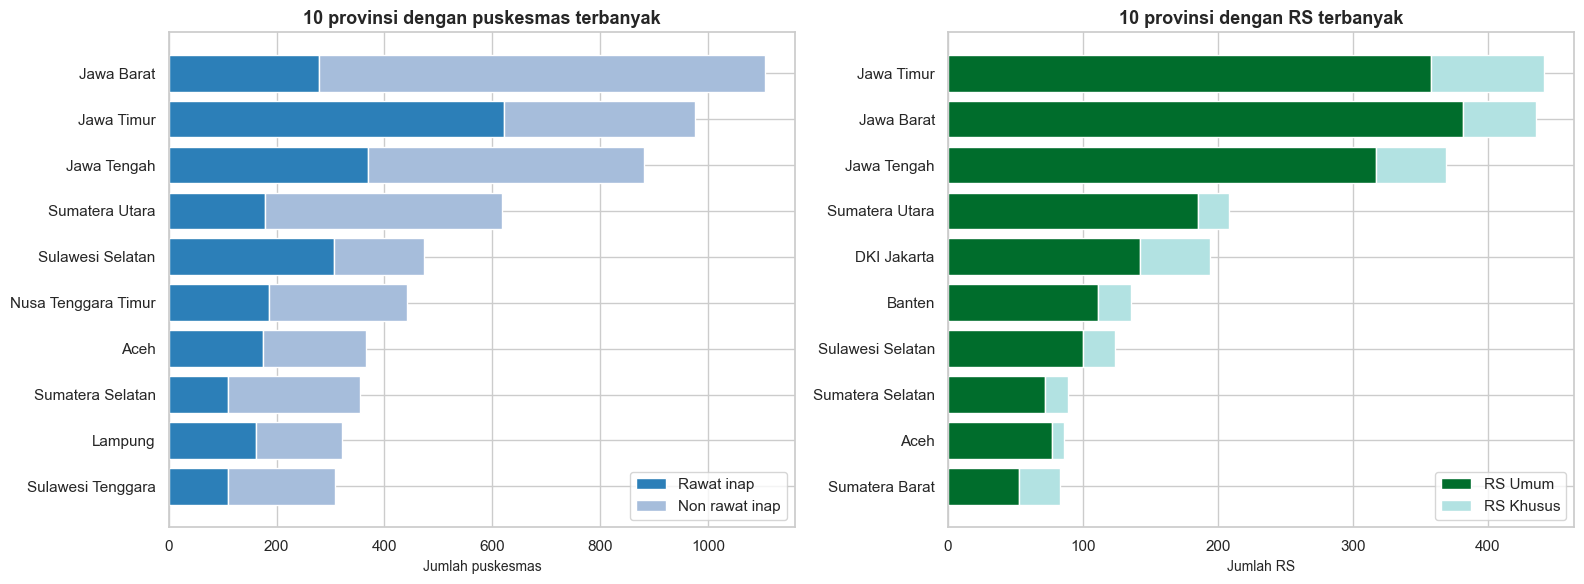

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top = rs2.nlargest(10, "total_pkm").sort_values("total_pkm")
axes[0].barh(top["Provinsi"], top["pkm_ri"], label="Rawat inap", color="#2c7fb8")
axes[0].barh(top["Provinsi"], top["pkm_nri"], left=top["pkm_ri"], label="Non rawat inap", color="#a6bddb")
axes[0].set_title("10 provinsi dengan puskesmas terbanyak")
axes[0].set_xlabel("Jumlah puskesmas")
axes[0].legend(loc="lower right")

top = rs2.nlargest(10, "total_rs_est").sort_values("total_rs_est")
axes[1].barh(top["Provinsi"], top["rsu"], label="RS Umum", color="#006d2c")
axes[1].barh(top["Provinsi"], top["rsk"].fillna(0), left=top["rsu"], label="RS Khusus", color="#b2e2e2")
axes[1].set_title("10 provinsi dengan RS terbanyak")
axes[1].set_xlabel("Jumlah RS")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

Memenuhi standar 1 puskesmas : 30.000 penduduk: 30 dari 38 provinsi


,Provinsi,total_pkm,pkm_needed,pkm_gap,pkm_ratio_std
11,Jawa Barat,1106,1705.46,-599.46,0.65
14,Jawa Timur,976,1411.73,-435.73,0.69
12,Jawa Tengah,881,1285.50,-404.50,0.69
10,DKI Jakarta,44,355.66,-311.66,0.12
15,Banten,253,421.38,-168.38,0.60
16,Bali,120,149.61,-29.61,0.80
17,Nusa Tenggara Barat,177,193.84,-16.84,0.91
13,DI Yogyakarta,121,126.76,-5.76,0.95
7,Lampung,322,320.79,1.21,1.00
8,Kepulauan Bangka Belitung,64,52.32,11.68,1.22


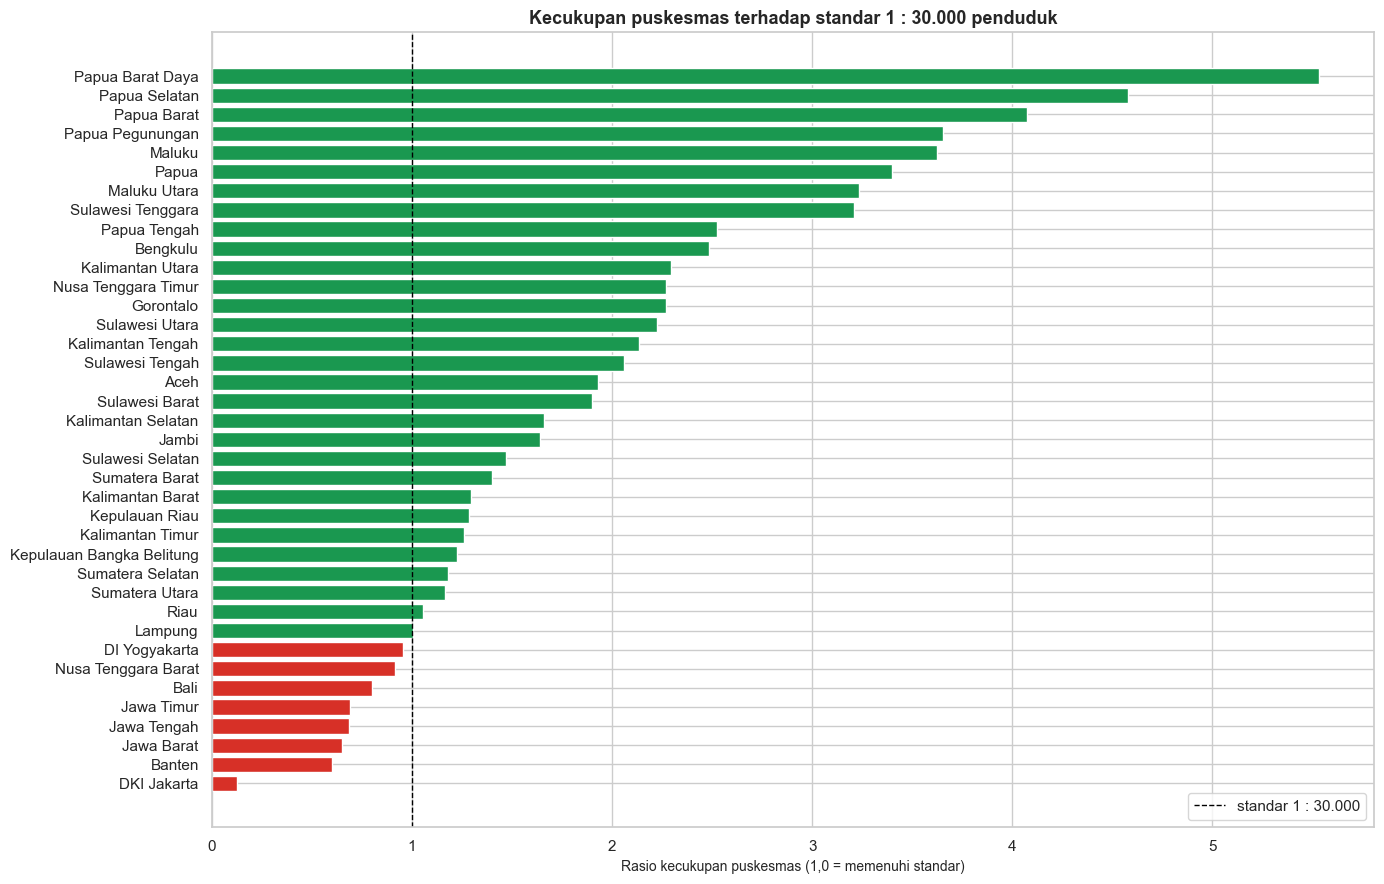

In [14]:
rs2["pkm_needed"] = rs2["pop"] / 30000
rs2["pkm_gap"] = rs2["total_pkm"] - rs2["pkm_needed"]
rs2["pkm_ratio_std"] = rs2["total_pkm"] * 30000 / rs2["pop"]

print("Memenuhi standar 1 puskesmas : 30.000 penduduk:",
      int((rs2.pkm_gap >= 0).sum()), "dari", len(rs2), "provinsi")
display(rs2[["Provinsi", "total_pkm", "pkm_needed", "pkm_gap", "pkm_ratio_std"]]
        .sort_values("pkm_gap").round(2).head(10))

plot = rs2.sort_values("pkm_ratio_std")
colors = ["#d73027" if v < 1 else "#1a9850" for v in plot["pkm_ratio_std"]]
fig, ax = plt.subplots(figsize=(14, 9))
ax.barh(plot["Provinsi"], plot["pkm_ratio_std"], color=colors)
ax.axvline(1, color="black", linestyle="--", linewidth=1, label="standar 1 : 30.000")
ax.set_xlabel("Rasio kecukupan puskesmas (1,0 = memenuhi standar)")
ax.set_title("Kecukupan puskesmas terhadap standar 1 : 30.000 penduduk")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Insight RS & puskesmas**
- Total nasional: **2.770 RSU + 514 RS Khusus = 3.284 RS**; **4.275 puskesmas rawat inap + 6.025 non rawat inap = 10.300 puskesmas**.
- **30 dari 38 provinsi** memenuhi standar 1 puskesmas : 30.000 penduduk. Yang gagal justru provinsi padat: DKI, Jawa Barat, Jawa Tengah, DI Yogyakarta, Jawa Timur, Banten, Bali, NTB.
- **DKI Jakarta** hanya punya 44 puskesmas untuk 10,7 juta jiwa (1 : 242.000), tetapi 44 puskesmas tersebut setara dengan 44 kecamatan. Jadi DKI memenuhi aturan **minimal 1 puskesmas per kecamatan**, tetapi jauh dari rasio penduduk; DKI mengandalkan RS, klinik, dan apotek.
- Rasio puskesmas per 100.000 penduduk: **0,41 (DKI)** sampai **18,44 (Papua Barat Daya)**; median 5,50. Rasio tinggi di Papua sebagian besar karena populasinya kecil, bukan karena fasilitasnya banyak.
- Rasio RSU per 100.000: **0,53 (Papua Pegunungan)** sampai **2,35 (Papua Barat)**; median 1,30.
- Komposisi RS Khusus: tertinggi Sumatera Barat 36,1%, DKI 26,8%; terendah Maluku 3,4%, NTT/Gorontalo 4,5%.
- Komposisi puskesmas rawat inap: tertinggi NTB 87,0%, Papua Selatan 69,4%; terendah DKI 4,5%, Papua Pegunungan 12,6%.
- **Peringatan**: 6 provinsi tidak punya nilai RS Khusus. `total_rs_est` menganggapnya 0, sehingga rasio RS di 6 provinsi itu bisa **underestimate**.

## 7. GeoJSON ADM2 (batas kabupaten/kota)

In [15]:
geo = gpd.read_file(RAW / "geoBoundaries-IDN-ADM2_simplified.geojson")
print("Shape :", geo.shape)
print("CRS   :", geo.crs)
print("Tipe geometri:", geo.geometry.geom_type.value_counts().to_dict())
print("Valid :", bool(geo.geometry.is_valid.all()), "| Kosong:", int(geo.geometry.is_empty.sum()))
print("Bounds:", [round(v, 3) for v in geo.total_bounds])
print("shapeName unik:", geo.shapeName.nunique(), "| duplikat:", int(geo.shapeName.duplicated().sum()))
print("shapeID unik  :", geo.shapeID.nunique(), "| duplikat:", int(geo.shapeID.duplicated().sum()))

NON_ADMIN = ["Hutan", "Wadung Kedungombo", "Waduk Cirata", "Danau", "Danau Toba"]
print("\nFitur non-administratif:")
display(geo[geo.shapeName.isin(NON_ADMIN)][["shapeName"]].reset_index(drop=True))

geo_admin = geo[~geo.shapeName.isin(NON_ADMIN)].copy()
geo_admin["area_km2"] = geo_admin.to_crs(6933).area / 1e6

print("Jumlah kab/kota setelah filter:", len(geo_admin))
print("Total luas GeoJSON :", f"{geo_admin['area_km2'].sum():,.0f} km²")
print("Luas dari BPS      :", f"{(pend['Jumlah Penduduk (Ribu)'] * 1000 / pend['Kepadatan Penduduk per km persegi (Km2)']).sum():,.0f} km²")
print("Gini luas kab/kota :", round(gini(geo_admin["area_km2"]), 3))
print("Top 10 luas share  :", round(geo_admin.nlargest(10, "area_km2")["area_km2"].sum() / geo_admin["area_km2"].sum() * 100, 1), "%")

display(top_bottom(geo_admin, "area_km2", n=5, cols=["shapeName", "area_km2"], decimals=1))

Shape : (519, 6)
CRS   : EPSG:4326
Tipe geometri: {'Polygon': 287, 'MultiPolygon': 232}


Valid : True | Kosong: 0
Bounds: [95.011, -11.008, 141.019, 6.077]
shapeName unik: 519 | duplikat: 0
shapeID unik  : 519 | duplikat: 0

Fitur non-administratif:


,shapeName
0,Danau
1,Danau Toba
2,Hutan
3,Waduk Cirata
4,Wadung Kedungombo


Jumlah kab/kota setelah filter: 514
Total luas GeoJSON : 1,889,428 km²
Luas dari BPS      : 1,879,320 km²
Gini luas kab/kota : 0.605
Top 10 luas share  : 16.1 %


,shapeName,area_km2,keterangan
0,Merauke,44006.3,tertinggi
1,Malinau,39913.0,tertinggi
2,Kutai Timur,31455.0,tertinggi
3,Kapuas Hulu,31119.9,tertinggi
4,Ketapang,29745.2,tertinggi
5,Kepulauan Seribu,7.9,terendah
6,Kota Sibolga,10.9,terendah
7,Kota Magelang,18.0,terendah
8,Kota Mojokerto,20.2,terendah
9,Kota Padang Panjang,21.1,terendah


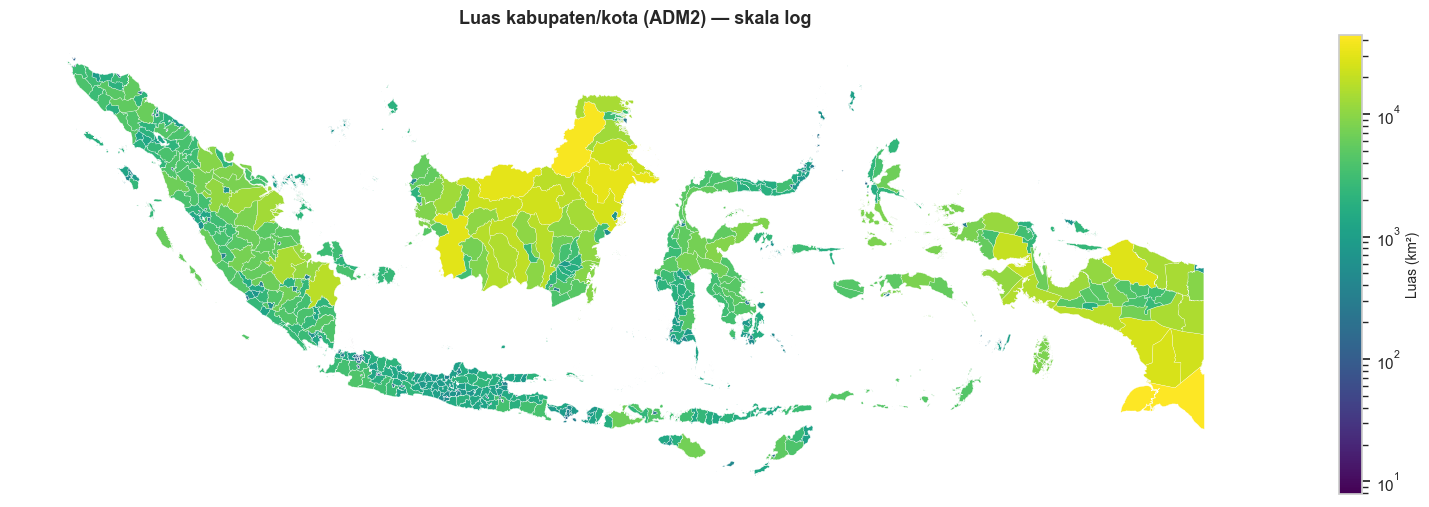

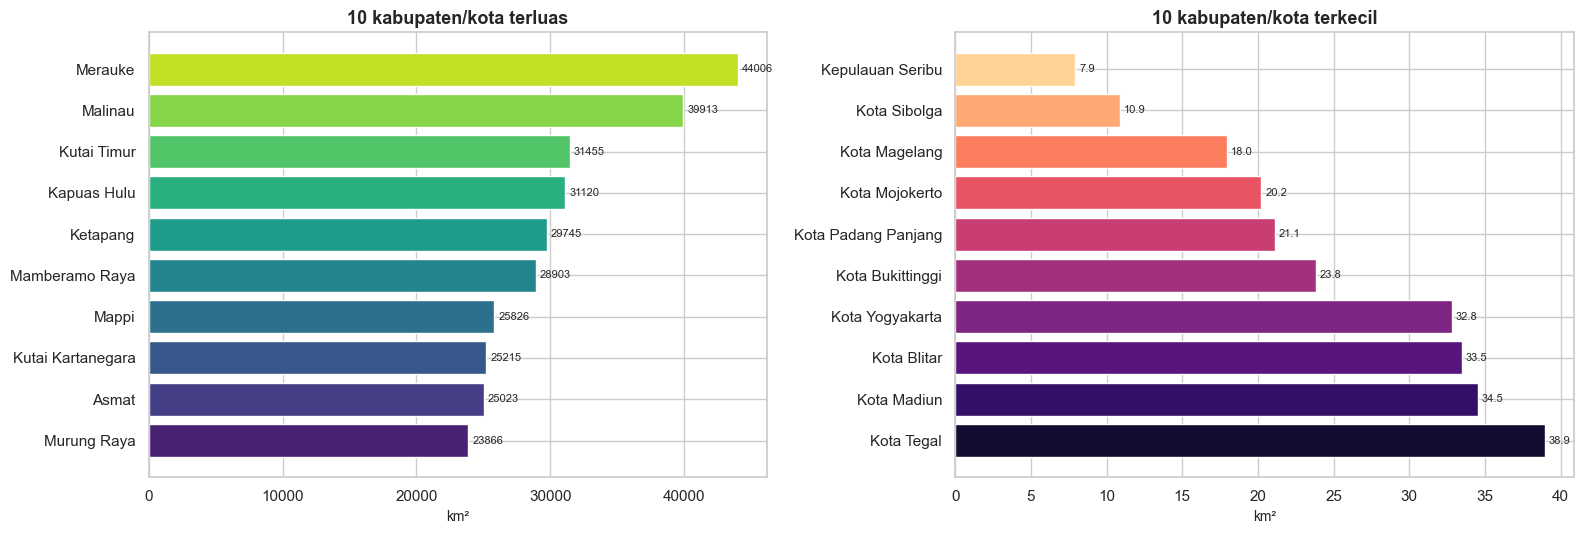

In [16]:
fig, ax = plt.subplots(figsize=(16, 8))
geo_admin.plot(
    column="area_km2", cmap="viridis",
    norm=LogNorm(vmin=geo_admin["area_km2"].min(), vmax=geo_admin["area_km2"].max()),
    linewidth=0.2, edgecolor="white", legend=True,
    legend_kwds={"label": "Luas (km²)", "shrink": 0.6}, ax=ax,
)
ax.set_title("Luas kabupaten/kota (ADM2) — skala log")
ax.set_axis_off()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
top = geo_admin.nlargest(10, "area_km2").sort_values("area_km2")
axes[0].barh(top["shapeName"], top["area_km2"], color=sns.color_palette("viridis", 10))
axes[0].set_title("10 kabupaten/kota terluas")
axes[0].set_xlabel("km²")
axes[0].bar_label(axes[0].containers[0], fmt="%.0f", padding=3, fontsize=8)

bot = geo_admin.nsmallest(10, "area_km2").sort_values("area_km2", ascending=False)
axes[1].barh(bot["shapeName"], bot["area_km2"], color=sns.color_palette("magma", 10))
axes[1].set_title("10 kabupaten/kota terkecil")
axes[1].set_xlabel("km²")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f", padding=3, fontsize=8)

plt.tight_layout()
plt.show()

**Insight GeoJSON**
- File berisi **519 fitur**: **514 kabupaten/kota + 5 fitur non-administratif** (`Hutan`, `Wadung Kedungombo`, `Waduk Cirata`, `Danau`, `Danau Toba`). Setelah 5 fitur itu dibuang, jumlahnya **tepat 514**, sesuai jumlah kabupaten/kota Indonesia.
- Semua geometri **valid**, tidak ada nama/ID duplikat, CRS **EPSG:4326**, bounds 95,01–141,02 BT dan -11,01–6,08 LS.
- Luas total 514 kab/kota = **1.889.000 km²**, sementara luas turunan dari populasi/kepadatan BPS = **1.879.000 km²**; selisih **0,5%** (wajar karena geometri disederhanakan dan kepadatan dibulatkan).
- **Merauke** terluas (44.006 km²); **Kepulauan Seribu** terkecil (7,9 km²). Gini luas **0,604**; 10 kab/kota terluas mencakup **16,1%** luas total.
- **Keterbatasan penting**: GeoJSON hanya punya `shapeName`, `shapeISO`, `shapeID`, `shapeGroup`, `shapeType`. **Tidak ada nama provinsi atau kode BPS**. Untuk join ke data provinsi, perlu ADM1 (batas provinsi) atau spatial join.
- Geometri disederhanakan (257.270 titik), jadi luas dan bentuk bisa sedikit berbeda dari batas resmi BIG/BPS.

## 8. Integrasi & indikator turunan

In [17]:
master = (pend.merge(desa, on="Provinsi")
              .merge(sar, on="Provinsi")
              .merge(rs, on="Provinsi"))

master["pop"] = master["Jumlah Penduduk (Ribu)"] * 1000
master["area_km2"] = master["pop"] / master["Kepadatan Penduduk per km persegi (Km2)"]
master["total_rs"] = master.rsu + master.rsk
master["total_rs_est"] = master.rsu + master.rsk.fillna(0)
master["total_pkm"] = master.pkm_ri + master.pkm_nri
master["total_faskes_est"] = master.total_rs_est + master.total_pkm

master["rs_per100k"] = master.total_rs_est / master["pop"] * 1e5
master["pkm_per100k"] = master.total_pkm / master["pop"] * 1e5
master["faskes_per100k"] = master.total_faskes_est / master["pop"] * 1e5
master["rs_per_1000km2"] = master.total_rs_est / master.area_km2 * 1000
master["pkm_per_1000km2"] = master.total_pkm / master.area_km2 * 1000
master["faskes_per_1000km2"] = master.total_faskes_est / master.area_km2 * 1000

master["pop_per_pkm"] = master["pop"] / master.total_pkm
master["pop_per_desa"] = master["pop"] / master["Jumlah Desa"]
master["desa_pkm_pct"] = master.desa_pkm / master["Jumlah Desa"] * 100
master["desa_rs_pct"] = master.desa_rs / master["Jumlah Desa"] * 100

master["pkm_needed"] = master["pop"] / 30000
master["pkm_gap"] = master.total_pkm - master.pkm_needed
master["pkm_ratio_std"] = master.total_pkm * 30000 / master["pop"]

master["pop_share"] = master["pop"] / master["pop"].sum() * 100
master["faskes_share"] = master.total_faskes_est / master.total_faskes_est.sum() * 100
master["faskes_share_ratio"] = master.faskes_share / master.pop_share
master["pkm_ri_share"] = master.pkm_ri / master.total_pkm * 100
master["rsk_share"] = master.rsk / master.total_rs_est * 100

print("Master shape:", master.shape)
display(master[["Provinsi", "pop", "total_rs_est", "total_pkm", "rs_per100k",
                "pkm_per100k", "desa_pkm_pct", "faskes_per_1000km2", "pkm_ratio_std"]]
        .head(10).round(2))

Master shape: (38, 42)


,Provinsi,pop,total_rs_est,total_pkm,rs_per100k,pkm_per100k,desa_pkm_pct,faskes_per_1000km2,pkm_ratio_std
0,Aceh,5695900.0,86.0,366,1.51,6.43,5.67,7.94,1.93
1,Sumatera Utara,15978600.0,208.0,619,1.30,3.87,10.14,11.44,1.16
2,Sumatera Barat,5991600.0,83.0,280,1.39,4.67,21.91,8.60,1.40
3,Riau,6892400.0,81.0,242,1.18,3.51,12.89,3.61,1.05
4,Jambi,3811700.0,45.0,208,1.18,5.46,13.18,5.18,1.64
5,Sumatera Selatan,9017100.0,89.0,354,0.99,3.93,10.78,5.11,1.18
6,Bengkulu,2163300.0,28.0,179,1.29,8.27,11.83,10.33,2.48
7,Lampung,9623800.0,83.0,322,0.86,3.35,12.06,12.08,1.00
8,Kepulauan Bangka Belitung,1569700.0,29.0,64,1.85,4.08,16.54,5.57,1.22
9,Kepulauan Riau,2243100.0,39.0,96,1.74,4.28,22.33,16.55,1.28


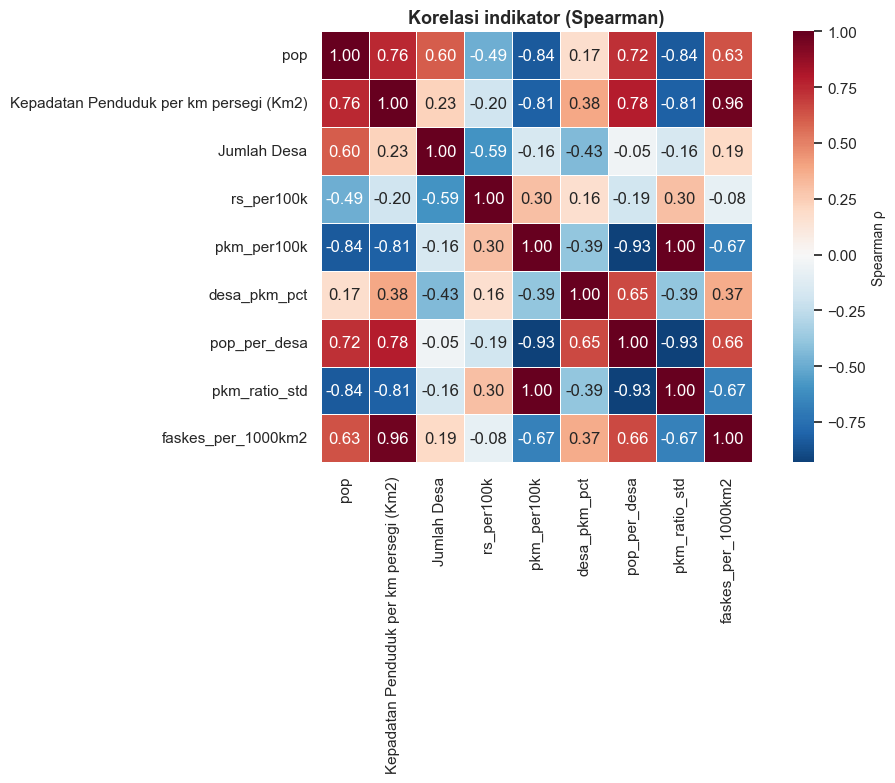

In [18]:
corr_cols = [
    "pop", "Kepadatan Penduduk per km persegi (Km2)", "Jumlah Desa",
    "rs_per100k", "pkm_per100k", "desa_pkm_pct", "pop_per_desa",
    "pkm_ratio_std", "faskes_per_1000km2",
]
corr = master[corr_cols].corr(method="spearman")

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5, cbar_kws={"label": "Spearman ρ"})
plt.title("Korelasi indikator (Spearman)")
plt.tight_layout()
plt.show()

**Insight korelasi (Spearman)**
- `pkm_per100k` vs `pop_per_desa`: **-0,93**; vs kepadatan: **-0,81**; vs populasi: **-0,84**. Semakin urban/padat, semakin **rendah** rasio puskesmas per kapita.
- `rs_per100k` vs kepadatan hanya **-0,20** dan vs `pop_per_desa` **-0,19** — sebaran RS per kapita relatif tidak sesensitif puskesmas terhadap urbanitas. RS cenderung mengikuti kota/provinsi, bukan kepadatan murni.
- `desa_pkm_pct` vs `pop_per_desa`: **+0,65** — provinsi urban punya cakupan desa ber-puskesmas lebih tinggi, meskipun rasio per kapitanya rendah. Dua metrik ini bisa **berlawanan arah**.
- `faskes_per_1000km2` vs kepadatan: **+0,96** — hampir definisional; metrik per luas sangat didominasi kepadatan.
- `pkm_per100k` vs `desa_pkm_pct`: **-0,39** — provinsi dengan rasio per kapita tinggi justru cenderung punya cakupan desa rendah (Papua/Maluku), dan sebaliknya (Jawa/DKI).
- **Implikasi**: memilih satu metrik sama dengan memilih narasi. Dashboard harus menampilkan beberapa lensa sekaligus.

### 8.1 Lorenz curve & Gini: absolut vs per kapita

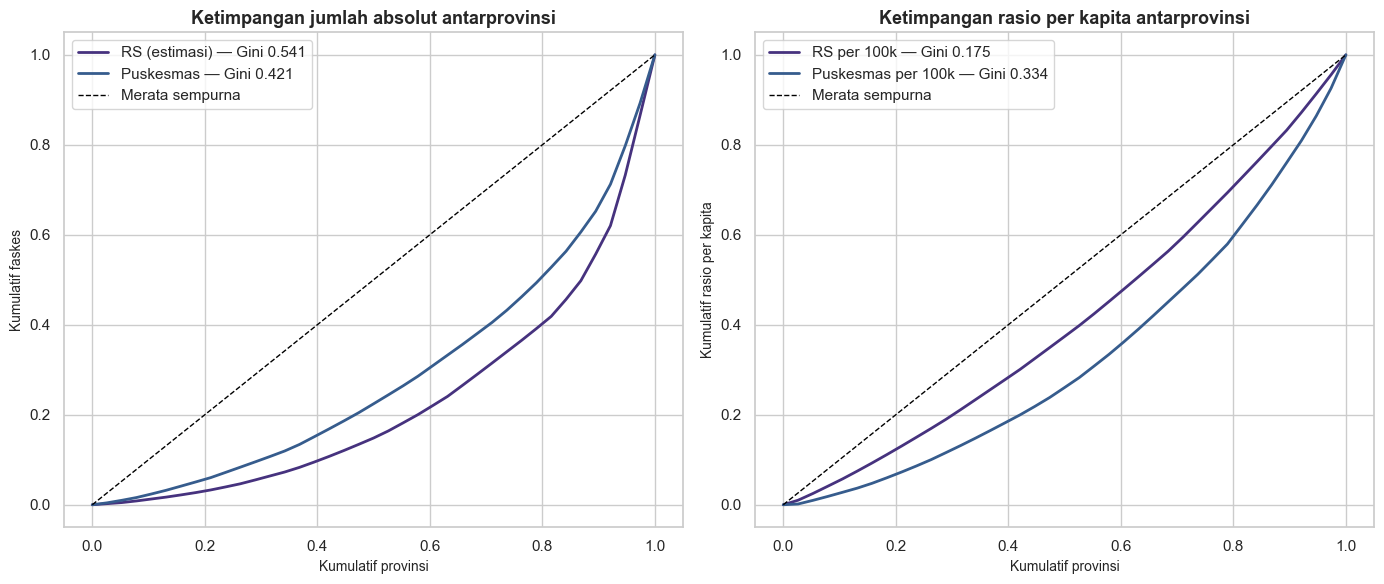

,indikator,n,gini,cv,theil
0,total_rs_est,38,0.541,1.255,0.533
1,total_pkm,38,0.421,0.911,0.309
2,total_faskes_est,38,0.428,0.973,0.333
3,rs_per100k,38,0.175,0.313,0.048
4,pkm_per100k,38,0.334,0.624,0.180
5,faskes_per100k,38,0.285,0.531,0.128


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for col, label in [("total_rs_est", "RS (estimasi)"), ("total_pkm", "Puskesmas")]:
    p, c = lorenz(master[col])
    axes[0].plot(p, c, linewidth=2, label=f"{label} — Gini {gini(master[col]):.3f}")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Merata sempurna")
axes[0].set_title("Ketimpangan jumlah absolut antarprovinsi")
axes[0].set_xlabel("Kumulatif provinsi")
axes[0].set_ylabel("Kumulatif faskes")
axes[0].legend()

for col, label in [("rs_per100k", "RS per 100k"), ("pkm_per100k", "Puskesmas per 100k")]:
    vals = master[col].dropna()
    p, c = lorenz(vals)
    axes[1].plot(p, c, linewidth=2, label=f"{label} — Gini {gini(vals):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="Merata sempurna")
axes[1].set_title("Ketimpangan rasio per kapita antarprovinsi")
axes[1].set_xlabel("Kumulatif provinsi")
axes[1].set_ylabel("Kumulatif rasio per kapita")
axes[1].legend()

plt.tight_layout()
plt.show()

rows = []
for col in ["total_rs_est", "total_pkm", "total_faskes_est", "rs_per100k", "pkm_per100k", "faskes_per100k"]:
    vals = master[col].dropna()
    rows.append({"indikator": col, "n": len(vals), "gini": gini(vals),
                 "cv": vals.std() / vals.mean(), "theil": theil(vals)})
display(pd.DataFrame(rows).round(3))

**Insight ketimpangan**
- **Jumlah absolut** jauh lebih timpang daripada **rasio per kapita**:
  - RS: Gini **0,49** (absolut) vs **0,15** (per kapita).
  - Puskesmas: Gini **0,42** (absolut) vs **0,33** (per kapita).
  - Total faskes: Gini **0,40** (absolut) vs **0,25** (per kapita).
- Artinya, ketimpangan jumlah faskes sebagian besar **mengikuti ukuran populasi**. Setelah dinormalisasi per kapita, ketimpangan turun drastis — kecuali puskesmas yang tetap paling timpang (Gini 0,33; CV 0,62).
- **Top 5 share**: populasi 55,95%, RS 51,35%, puskesmas 39,38%. Puskesmas lebih tersebar ke luar Jawa; RS lebih terkonsentrasi mengikuti populasi/kota.
- **Theil** memberikan urutan yang sama: RS per kapita 0,035 (paling merata), puskesmas per kapita 0,18 (paling timpang).
- Jangan memakai Gini jumlah absolut untuk mengklaim “faskes tidak merata” tanpa menyebut bahwa populasi juga timpang.

### 8.2 Tiga lensa: per kapita, per luas, per desa

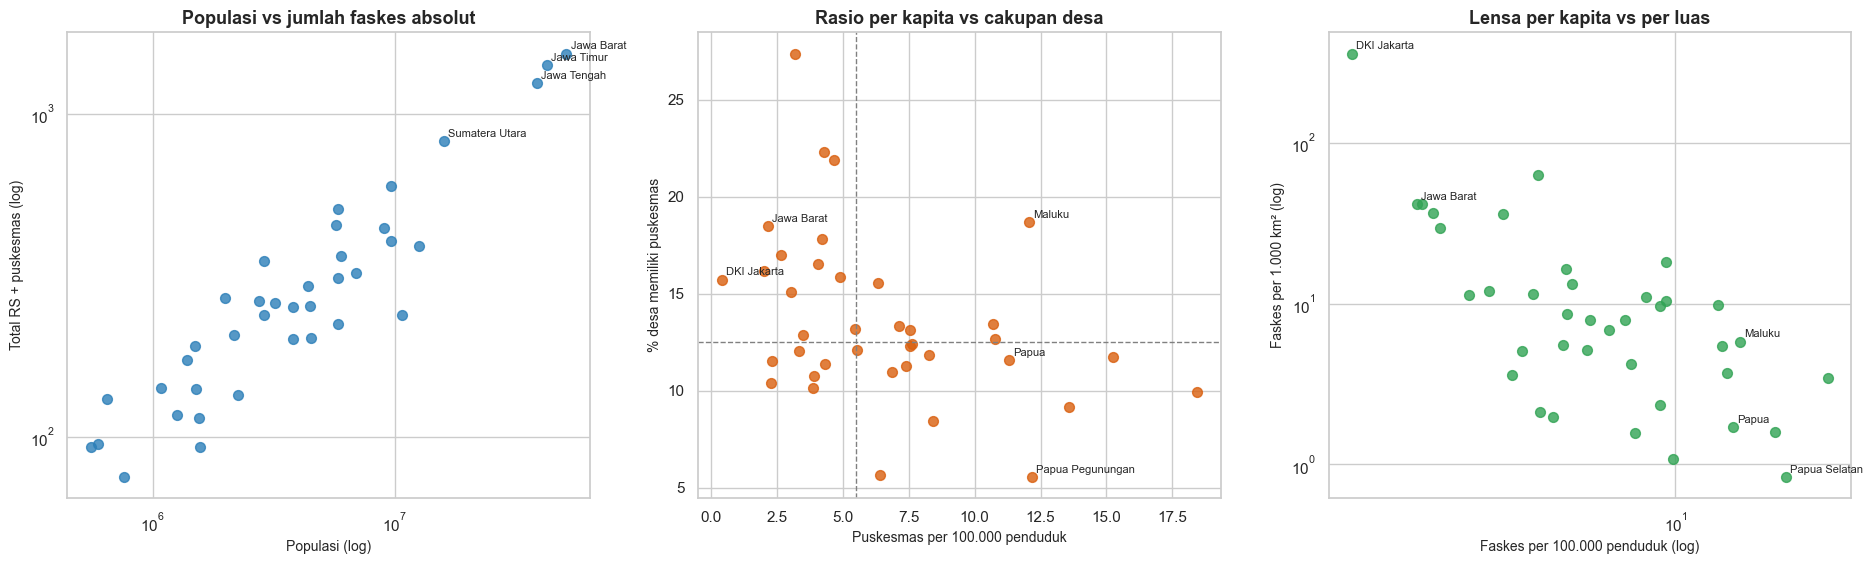

Korelasi peringkat per kapita vs per luas (Spearman):


,faskes_per100k,faskes_per_1000km2,pkm_per100k,pkm_per_1000km2
faskes_per100k,1.00,-0.63,0.99,-0.61
faskes_per_1000km2,-0.63,1.00,-0.67,1.00
pkm_per100k,0.99,-0.67,1.00,-0.64
pkm_per_1000km2,-0.61,1.00,-0.64,1.00


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))

axes[0].scatter(master["pop"], master["total_faskes_est"], s=50, alpha=0.8, color="#2c7fb8")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Populasi (log)")
axes[0].set_ylabel("Total RS + puskesmas (log)")
axes[0].set_title("Populasi vs jumlah faskes absolut")
for _, r in master.nlargest(4, "pop").iterrows():
    axes[0].annotate(r.Provinsi, (r["pop"], r.total_faskes_est), fontsize=8,
                     xytext=(3, 3), textcoords="offset points")

axes[1].scatter(master["pkm_per100k"], master["desa_pkm_pct"], s=50, alpha=0.8, color="#d95f0e")
axes[1].axvline(master.pkm_per100k.median(), color="gray", linestyle="--", linewidth=1)
axes[1].axhline(master.desa_pkm_pct.median(), color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("Puskesmas per 100.000 penduduk")
axes[1].set_ylabel("% desa memiliki puskesmas")
axes[1].set_title("Rasio per kapita vs cakupan desa")
for name in ["DKI Jakarta", "Papua", "Papua Pegunungan", "Jawa Barat", "Maluku"]:
    r = master[master.Provinsi == name].iloc[0]
    axes[1].annotate(name, (r.pkm_per100k, r.desa_pkm_pct), fontsize=8,
                     xytext=(3, 3), textcoords="offset points")

axes[2].scatter(master["faskes_per100k"], master["faskes_per_1000km2"], s=50, alpha=0.8, color="#31a354")
axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_xlabel("Faskes per 100.000 penduduk (log)")
axes[2].set_ylabel("Faskes per 1.000 km² (log)")
axes[2].set_title("Lensa per kapita vs per luas")
for name in ["DKI Jakarta", "Papua Selatan", "Jawa Barat", "Papua", "Maluku"]:
    r = master[master.Provinsi == name].iloc[0]
    axes[2].annotate(name, (r.faskes_per100k, r.faskes_per_1000km2), fontsize=8,
                     xytext=(3, 3), textcoords="offset points")

plt.tight_layout()
plt.show()

print("Korelasi peringkat per kapita vs per luas (Spearman):")
display(master[["faskes_per100k", "faskes_per_1000km2", "pkm_per100k", "pkm_per_1000km2"]]
        .corr(method="spearman").round(2))

**Insight tiga lensa**
- **Per kapita vs per luas berbanding terbalik**: korelasi peringkat `pkm_per100k` vs `pkm_per_1000km2` = **-0,64**; `faskes_per100k` vs `faskes_per_1000km2` = **-0,63**. Provinsi yang “baik” per kapita sering “buruk” per luas, dan sebaliknya.
- **DKI Jakarta**: 359,8 faskes per 1.000 km² (tertinggi), tetapi hanya 0,47x share populasi dan 0,41 puskesmas per 100.000 (terendah). DKI unggul secara **kepadatan fasilitas**, bukan rasio per kapita.
- **Papua Selatan**: 0,83 faskes per 1.000 km² (terendah), tetapi 15,25 puskesmas per 100.000 dan 3,53x share populasi. Provinsi ini “tinggi” per kapita karena populasinya kecil, tetapi **luasnya sangat besar**.
- **Jawa Barat**: 17,81% populasi, 11,35% faskes, 0,64x share populasi. Secara absolut faskesnya banyak, tetapi **di bawah proporsi populasi**.
- **Maluku, Papua, Sulawesi Tenggara** punya share faskes >2,5x share populasi — sebagian karena banyak puskesmas tersebar di wilayah kepulauan.
- **Kesimpulan metodologis**: “rata” harus didefinisikan dulu: rata per orang, per km², per desa, atau per kecamatan. Dashboard yang baik menampilkan semuanya.

### 8.3 Kuadran: dua jenis tantangan pemerataan

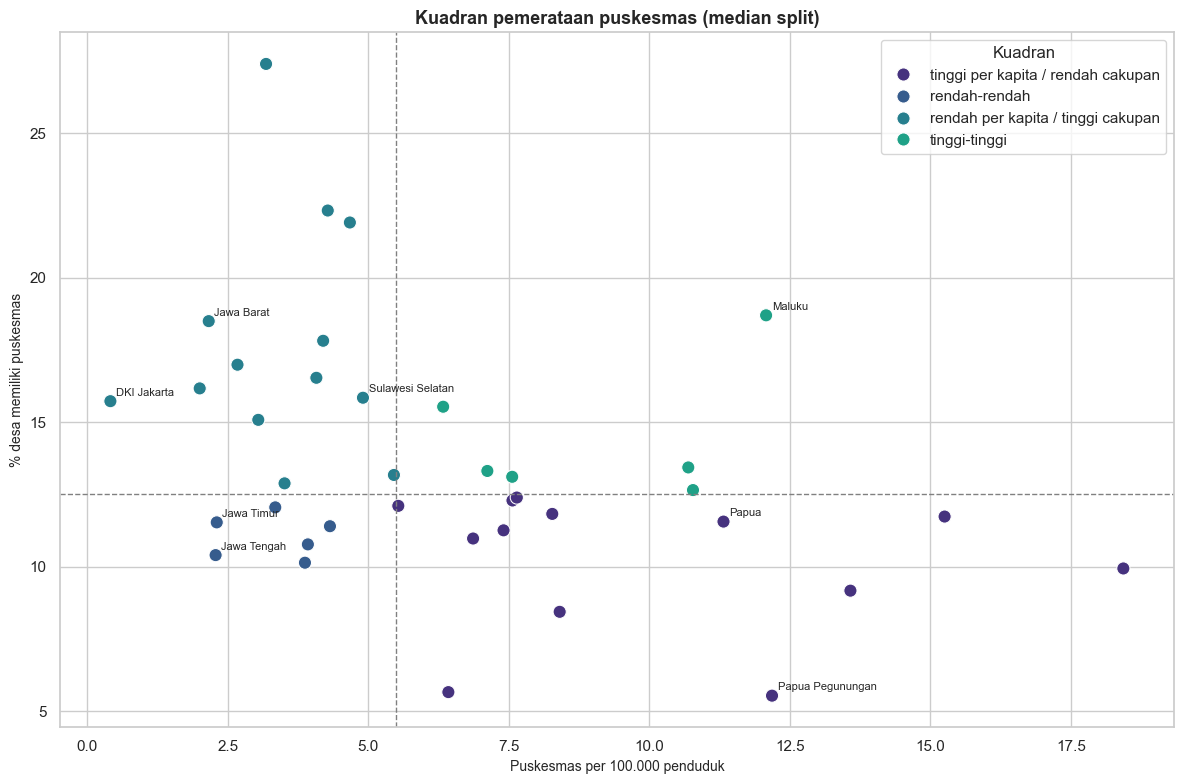

,kuadran,jumlah_provinsi,populasi_juta,provinsi
0,rendah per kapita / tinggi cakupan,13,123.2,"Sumatera Barat, Riau, Jambi, Kepulauan Bangka ..."
1,rendah-rendah,6,121.4,"Sumatera Utara, Sumatera Selatan, Lampung, Jaw..."
2,tinggi per kapita / rendah cakupan,13,30.6,"Aceh, Bengkulu, Nusa Tenggara Timur, Kalimanta..."
3,tinggi-tinggi,6,12.0,"Kalimantan Tengah, Sulawesi Tenggara, Gorontal..."


In [21]:
med_pkm = master.pkm_per100k.median()
med_cov = master.desa_pkm_pct.median()

master["kuadran"] = np.select(
    [
        (master.pkm_per100k >= med_pkm) & (master.desa_pkm_pct >= med_cov),
        (master.pkm_per100k >= med_pkm) & (master.desa_pkm_pct < med_cov),
        (master.pkm_per100k < med_pkm) & (master.desa_pkm_pct >= med_cov),
    ],
    [
        "tinggi-tinggi",
        "tinggi per kapita / rendah cakupan",
        "rendah per kapita / tinggi cakupan",
    ],
    default="rendah-rendah",
)

fig, ax = plt.subplots(figsize=(12, 8))
sns.scatterplot(data=master, x="pkm_per100k", y="desa_pkm_pct",
                hue="kuadran", s=90, ax=ax)
ax.axvline(med_pkm, color="gray", linestyle="--", linewidth=1)
ax.axhline(med_cov, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Puskesmas per 100.000 penduduk")
ax.set_ylabel("% desa memiliki puskesmas")
ax.set_title("Kuadran pemerataan puskesmas (median split)")
for name in ["DKI Jakarta", "Jawa Barat", "Jawa Timur", "Jawa Tengah",
             "Papua", "Papua Pegunungan", "Maluku", "Sulawesi Selatan"]:
    r = master[master.Provinsi == name].iloc[0]
    ax.annotate(name, (r.pkm_per100k, r.desa_pkm_pct), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.legend(title="Kuadran", loc="upper right")
plt.tight_layout()
plt.show()

ring = (master.groupby("kuadran")
        .agg(jumlah_provinsi=("Provinsi", "count"),
             populasi_juta=("pop", lambda s: round(s.sum() / 1e6, 1)),
             provinsi=("Provinsi", lambda s: ", ".join(s)))
        .reset_index()
        .sort_values("populasi_juta", ascending=False))
display(ring)

**Insight kuadran**
- **Rendah per kapita / tinggi cakupan** (13 provinsi, **42,9% populasi**): DKI, Banten, Jawa Barat, Bali, NTB, DIY, Riau, Babel, Kaltim, Kepri, Sumbar, Sulsel, Jambi. Tantangannya **kepadatan**: banyak desa sudah punya puskesmas, tetapi satu puskesmas melayani terlalu banyak orang.
- **Rendah-rendah** (6 provinsi, **42,3% populasi**): Jawa Tengah, Jawa Timur, Lampung, Sumatera Utara, Sumatera Selatan, Kalimantan Barat. Ini **prioritas utama** karena populasi besar dan kedua indikator di bawah median.
- **Tinggi per kapita / rendah cakupan** (13 provinsi, **10,7% populasi**): mayoritas Papua, Maluku, Kaltara, NTT, Sulawesi Tengah/Utara, Bengkulu, Aceh. Tantangannya **akses geografis**: rasio per kapita terlihat aman, tetapi banyak desa tidak memiliki puskesmas dan wilayahnya luas.
- **Tinggi-tinggi** (6 provinsi, **4,2% populasi**): Sulbar, Kalteng, Gorontalo, Sultra, Malut, Maluku.
- **Catatan**: ini analisis eksploratif dengan median split, bukan indeks resmi. “Cakupan desa” mengukur keberadaan di desa, bukan waktu tempuh.

## 9. Ringkasan insight

1. **Data bersih = 38 provinsi**; keempat CSV saling konsisten dan totalnya sama persis dengan baris `Indonesia`.
2. Skala nasional: **84.291 desa**, **10.300 puskesmas**, **3.284 RS** (2.770 umum + 514 khusus).
3. **87,84% desa tidak memiliki puskesmas** dan **96,68% tidak memiliki RS**; ini mengukur keberadaan di desa, bukan akses.
4. Sarana paling tersebar: **Pustu (29,44%)**, **Apotek (22,54%)**, **Puskesmas (12,16%)**, **Klinik Pratama (10,63%)**.
5. Sarana paling langka: **Balai Kesehatan (0,11%)**, **Klinik Utama (1,78%)**, **RS (3,32%)**.
6. **DKI Jakarta** unggul untuk RS, apotek, klinik, dan pustu, tetapi cakupan puskesmas hanya 16,53% desa.
7. **Papua Pegunungan** terendah untuk hampir semua jenis sarana; cakupan puskesmas 5,54%, RS 0,34%, apotek 0,42%.
8. Rasio puskesmas per 100.000: **0,41 (DKI)** sampai **18,44 (Papua Barat Daya)**; median 5,50.
9. Rasio RSU per 100.000: **0,53 (Papua Pegunungan)** sampai **2,35 (Papua Barat)**; median 1,30.
10. **30/38 provinsi** memenuhi standar 1 puskesmas : 30.000 penduduk; 8 provinsi padat gagal.
11. **DKI** punya 44 puskesmas = 44 kecamatan, jadi memenuhi aturan minimal per kecamatan, tetapi rasio penduduknya 1 : 242.000.
12. Ketimpangan absolut: Gini RS **0,49**, puskesmas **0,42**, total **0,40**.
13. Ketimpangan per kapita: Gini RS **0,15**, puskesmas **0,33**, total **0,25** — jauh lebih rendah, tetapi puskesmas tetap paling timpang.
14. **Top 5 populasi = 55,95%**, top 5 RS = **51,35%**, top 5 puskesmas = **39,38%**; puskesmas lebih tersebar, RS lebih mengikuti populasi/kota.
15. **Per kapita vs per luas berbanding terbalik** (ρ = -0,64 untuk puskesmas): tidak ada satu ukuran “rata” yang netral.
16. **DKI** = 359,8 faskes/1.000 km² (tertinggi) tetapi 0,47x share populasi; **Papua Selatan** = 0,83 faskes/1.000 km² (terendah) tetapi 3,53x share populasi.
17. **Populasi per desa vs puskesmas per kapita = -0,93**: semakin urban, semakin rendah rasio per kapita.
18. **6 provinsi “rendah-rendah”** (Jateng, Jatim, Lampung, Sumut, Sumsel, Kalbar) menampung **42,3% populasi** → prioritas primary care.
19. **13 provinsi “tinggi per kapita / rendah cakupan”** (mayoritas Papua, Maluku, Kaltara, NTT) menampung **10,7% populasi** → prioritas akses geografis.
20. **13 provinsi “rendah per kapita / tinggi cakupan”** (Jawa/Bali/Sumatra kota) menampung **42,9% populasi** → tantangan kepadatan, bukan kekurangan faskes absolut.
21. **GeoJSON**: 519 fitur = **514 kab/kota + 5 fitur non-admin**; luas total 1,889 juta km² vs 1,879 juta km² dari BPS (selisih 0,5%); tidak ada atribut provinsi/kode BPS.
22. **Data belum cukup untuk mengklaim pemerataan riil**: belum ada data faskes per kab/kota, koordinat faskes, tempat tidur, tenaga kesehatan, waktu tempuh, dan standar pembanding selain 1 : 30.000.

## 10. Data quality & hal yang perlu diperhatikan

**Struktur & pembersihan**
- Setiap CSV punya baris `Indonesia`, baris kosong, `Keterangan`, dan catatan kaki. Wajib dibuang sebelum analisis.
- Karakter `�` adalah missing, bukan angka. Jangan langsung `fillna(0)` tanpa flag.
- `Persentase Penduduk` berjumlah **99,96%**, bukan 100% — pembulatan, bukan error.

**Missing**
- `Jumlah Rumah Sakit Khusus`: 6 provinsi (Kaltara, Papua Barat, Papua Barat Daya, Papua Selatan, Papua Tengah, Papua Pegunungan).
- `Balai Kesehatan`: 21 provinsi.
- Untuk RS Khusus, gunakan `total_rs_est` (anggap 0) **hanya untuk eksplorasi**, dan sebutkan asumsinya. Untuk analisis utama, pertimbangkan RSU saja.

**Tahun & definisi**
- Penduduk = proyeksi **2026**; desa/sarana/RS = **2025**; catatan RS menyebut puskesmas semester I **2024** (teks Inggris menyebut 2023). Jangan mencampur tanpa menyebut tahun.
- `Desa/Kelurahan Yang Memiliki Sarana Kesehatan` berarti fasilitas **berada di desa**, bukan waktu tempuh atau akses efektif.
- Cakupan tiap jenis sarana **tidak bisa dijumlahkan** karena satu desa bisa punya beberapa fasilitas dan overlap tidak diketahui.
- `desa_pkm > total_pkm` terjadi di **19 provinsi**; `desa_rs > total_rs` di **Maluku**. Ini indikasi perbedaan definisi/tahun antar-sumber, bukan otomatis error.
- `Jumlah Desa` 2025 vs `Puskesmas` 2024 vs `Penduduk` 2026: perbedaan tahun bisa menggeser rasio kecil.

**Wilayah**
- 4 provinsi baru hasil pemekaran Papua (Papua Selatan, Papua Tengah, Papua Pegunungan, Papua Barat Daya) ada di data; sebagian data 2024/2025 mungkin masih dipecah dari provinsi induk.
- **152 desa** di Papua, Papua Tengah, dan Papua Pegunungan tidak berhasil dicacah (catatan Podes).
- GeoJSON 519 fitur: 5 di antaranya bukan kab/kota (`Hutan`, `Wadung Kedungombo`, `Waduk Cirata`, `Danau`, `Danau Toba`).
- GeoJSON **tidak punya nama provinsi/kode BPS**; perlu ADM1 atau spatial join.
- Geometri disederhanakan; luas dan bentuk bisa berbeda dari batas resmi BIG.

**Metodologi**
- **RS dan puskesmas tidak setara**; menjumlahkannya menjadi “total faskes” hanya boleh untuk gambaran kasar.
- Rasio per kapita, per luas, dan per desa memberi kesimpulan yang berbeda. Jangan memilih satu tanpa alasan.
- Standar 1 : 30.000 adalah **rasio penduduk**, bukan satu-satunya norma; Permenkes 19/2024 juga mensyaratkan minimal 1 puskesmas per kecamatan dan mempertimbangkan aksesibilitas.
- Data ini tidak punya **tempat tidur, tenaga kesehatan, jenis layanan, akreditasi, waktu tempuh, atau anggaran** — semua itu penting untuk menilai mutu dan akses.
- Korelasi bukan kausalitas; Spearman hanya menunjukkan arah hubungan peringkat.

## 11. Rekomendasi & next steps

**Untuk menjawab “sudah rata atau belum” secara valid**
1. Tambahkan **data faskes per kabupaten/kota** (SIRS untuk RS; KMK Puskesmas untuk puskesmas).
2. Tambahkan **penduduk per kabupaten/kota** (BPS WebAPI/proyeksi kab/kota).
3. Tambahkan **ADM1** atau lakukan spatial join agar GeoJSON ADM2 bisa dipetakan ke provinsi.
4. Tambahkan **Podes microdata** untuk jarak/waktu tempuh ke faskes.
5. Tambahkan **kapasitas**: tempat tidur, dokter/spesialis, jenis layanan, akreditasi.
6. Gunakan **standar normatif** (Permenkes 19/2024, RPJMN/Renstra) sebagai garis acuan.

**Analisis lanjutan yang disarankan**
- Hitung **Moran’s I** setelah data kab/kota dan batas provinsi tersedia.
- Buat **clustering** provinsi/kab/kota berdasarkan rasio, cakupan, dan akses.
- Bandingkan **tiga lensa** (per kapita, per luas, per desa) dalam dashboard.
- Buat **peta choropleth** per kapita dan per luas berdampingan untuk menunjukkan paradoks DKI vs Papua.
- Validasi temuan cakupan desa dengan **waktu tempuh** dari Podes/OSM.

**Untuk dashboard**
- Tampilkan KPI: total faskes, rasio per 100.000, cakupan desa, Gini/CV, jumlah desa tanpa faskes.
- Sediakan filter: provinsi, jenis faskes, tahun, lensa (per kapita/per luas/per desa).
- Tampilkan **ranking + deviasi dari median nasional**, bukan hanya ranking.
- Beri catatan kaki tentang missing RS Khusus, tahun data, dan definisi “memiliki sarana”.